# IT3091 Machine Learning — Diabetes 30-Day Readmission Project

**Group:** 2026-DS-61  
**Domain:** Healthcare  
**Track:** Guided Data Track  
**Dataset:** Diabetes 130-US Hospitals for Years 1999–2008  

## Project lenses
- **Primary lens:** 30-day readmission risk
- **Secondary lens:** Medication / treatment pattern analysis for readmission risk
- **Unit of analysis:** Inpatient encounter
- **Binary target:** `1 = readmitted <30 days`; `0 = >30 days or NO`

## Member ownership
| Part | Member | Main responsibility | Model |
|---|---|---|---|
| Member 1 | Rathnayake S.N.S. | Data Understanding & EDA | Logistic Regression |
| Member 2 | De Silva N.S.R. | Preprocessing & leakage control | Random Forest |
| Member 3 | Dewmith H.B.S. | Feature Engineering | XGBoost |
| Member 4 | Vishwajith U.K.S.B. | Secondary medication analysis | CatBoost |



In [1]:
#If your environment says xgboost or catboost is missing, uncomment and run once:
%pip install -q xgboost catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.1 MB/s eta 0:00:00


# PART 0 — GROUP
## 0. Project Setup, Problem Framing and Reproducibility

**Ownership: ALL MEMBERS**

### Business problem
Hospitals want to identify diabetic inpatient encounters at higher risk of readmission within 30 days after discharge so that discharge planning, follow-up, and resource allocation can be better supported.

### Primary task
Binary classification of whether an encounter will result in readmission within 30 days.

### Expected primary output
1. Predicted probability of `<30` readmission.
2. High-risk / low-risk classification using a justified operating threshold.

### Secondary task
Investigate associations between medication/treatment patterns and `<30` readmission without making causal claims.

In [2]:
# 0.1 Imports and global configuration

import sys
import platform
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("Python:", sys.version)
print("Platform:", platform.platform())


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


In [3]:
# 0.2 File paths
# Keep the notebook and both CSV files in the same folder.

DATA_PATH = Path("diabetic_data.csv")
MAPPING_PATH = Path("IDS_mapping.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Main dataset not found: {DATA_PATH.resolve()}")
if not MAPPING_PATH.exists():
    raise FileNotFoundError(f"Mapping file not found: {MAPPING_PATH.resolve()}")

print("Data file:", DATA_PATH.resolve())
print("Mapping file:", MAPPING_PATH.resolve())

Data file: /content/diabetic_data.csv
Mapping file: /content/IDS_mapping.csv


In [4]:
# 0.3 Load source data
# IMPORTANT: keep_default_na=False preserves the literal category "None"
# in max_glu_serum and A1Cresult. Only the dataset's explicit "?" marker
# will later be converted to missing values.

df_raw = pd.read_csv(DATA_PATH, keep_default_na=False)
ids_mapping_raw = pd.read_csv(MAPPING_PATH, keep_default_na=False)

print("Main dataset shape:", df_raw.shape)
print("Mapping dataset shape:", ids_mapping_raw.shape)
display(df_raw.head())
display(ids_mapping_raw.head())

Main dataset shape: (101766, 50)
Mapping dataset shape: (67, 2)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available


In [5]:
# 0.4 Dataset fingerprint for reproducibility

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

print("Dataset SHA-256:", sha256_file(DATA_PATH))
print("Mapping SHA-256:", sha256_file(MAPPING_PATH))

Dataset SHA-256: 0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97
Mapping SHA-256: f1bb82b471cb34649352597572c9b1fb00bd27f77b9f5a22a03dc3eb1039749e


In [6]:
# 0.5 Create binary target
# Positive class = readmitted within 30 days.

df = df_raw.copy()
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)

# Normalize columns that are numerically defined in the source dataset.
# This prevents mixed int/string dtypes from breaking EDA binning (pd.cut)
# while leaving true categorical columns such as age and diagnoses unchanged.
NUMERIC_SOURCE_COLUMNS = [
    "encounter_id", "patient_nbr",
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]

for col in NUMERIC_SOURCE_COLUMNS:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Numeric source columns normalized successfully.")

display(df[["readmitted", "readmit_30"]].value_counts().rename("count"))

Numeric source columns normalized successfully.


,,count
readmitted,readmit_30,
NO,0,54864
>30,0,35545
<30,1,11357


## 0.6 Decision Log

Record important decisions throughout the notebook.

| Decision | Options considered | Selected option | Reason / evidence | Owner |
|---|---|---|---|---|
| Target definition | 3-class vs binary | `<30` vs `>30 + NO` | Matches primary decision objective | Group |
| Split strategy | Random encounter split vs patient-group split | **Patient-group split** | Prevents repeated-patient leakage across train/validation/test | Member 2 |
| Main evaluation focus | Accuracy vs imbalance-aware metrics | **PR-AUC with recall/F2 support** | Positive class is the minority; accuracy alone is insufficient | Group |
| Final operating threshold | 0.50 vs tuned threshold | **0.42** | Selected on validation data by maximum F2 for recall-oriented screening | Group |

Final decisions are consolidated again in Appendix A.


## Notebook Execution Order

This master notebook is organized by **machine-learning dependency order**, not by member number. Member ownership is shown within the relevant stage/model. Run it from top to bottom.


---
# PART 1 — DATA UNDERSTANDING, DATA QUALITY & EDA

**Owner: Member 1 — Rathnayake S.N.S.**


## 1. Data Understanding

### Questions to answer
- What does one row represent?
- How many encounters and variables exist?
- Which variables are numerical, categorical, ordinal, identifiers, diagnoses, medications, and ID-coded categories?
- Which columns require `IDS_mapping.csv`?
- How many unique patients are represented?

In [7]:
# 1.1 Dataset overview

print("Rows, columns:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))
display(df.nunique(dropna=False).sort_values().to_frame("unique_values"))

Rows, columns: (101766, 51)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmit_30
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,Steady,No,No,No,No,No,Ch,Yes,NO,0


,dtype
encounter_id,int64
patient_nbr,int64
race,object
gender,object
age,object
weight,object
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64


,unique_values
citoglipton,1
examide,1
acetohexamide,2
glipizide-metformin,2
tolbutamide,2
readmit_30,2
metformin-rosiglitazone,2
glimepiride-pioglitazone,2
metformin-pioglitazone,2
troglitazone,2


In [8]:
# 1.2 Patient and encounter structure

print("Unique encounters:", df["encounter_id"].nunique())
print("Unique patients:", df["patient_nbr"].nunique())

encounters_per_patient = df.groupby("patient_nbr").size()
repeated_patients = (encounters_per_patient > 1).sum()
encounters_from_repeated = encounters_per_patient[encounters_per_patient > 1].sum()

print("Patients with >1 encounter:", repeated_patients)
print("Percentage of patients with >1 encounter:",
      round(100 * repeated_patients / encounters_per_patient.size, 2), "%")
print("Encounters belonging to repeated patients:", encounters_from_repeated)
print("Percentage of all encounters from repeated patients:",
      round(100 * encounters_from_repeated / len(df), 2), "%")

display(encounters_per_patient.describe().to_frame("encounters_per_patient"))

# This finding will inform Member 2's leakage-safe split decision.

Unique encounters: 101766
Unique patients: 71518
Patients with >1 encounter: 16773
Percentage of patients with >1 encounter: 23.45 %
Encounters belonging to repeated patients: 47021
Percentage of all encounters from repeated patients: 46.21 %


,encounters_per_patient
count,71518.000000
mean,1.422942
std,1.090740
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,40.000000


In [9]:
# 1.3 Parse IDS_mapping.csv into three lookup dictionaries

# The mapping file stores three mapping blocks in two columns rather than
# three separate CSV tables. This parser preserves the file's supplied labels.

mapping_df = ids_mapping_raw.copy()
first_col = mapping_df.columns[0]
second_col = mapping_df.columns[1]

header_names = {
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
}

mapping_dicts = {}
current_mapping = "admission_type_id"
mapping_dicts[current_mapping] = {}

for _, row in mapping_df.iterrows():
    raw_id = row[first_col]
    description = row[second_col]

    if isinstance(raw_id, str) and raw_id in header_names:
        current_mapping = raw_id
        mapping_dicts.setdefault(current_mapping, {})
        continue

    if pd.isna(raw_id):
        continue

    try:
        code_value = int(float(raw_id))
    except (TypeError, ValueError):
        continue

    label = "Missing description" if pd.isna(description) else str(description)
    mapping_dicts[current_mapping][code_value] = label

for name, lookup in mapping_dicts.items():
    print(f"\n{name}: {len(lookup)} mapped codes")
    display(pd.DataFrame(sorted(lookup.items()), columns=[name, "description"]))


admission_type_id: 8 mapped codes


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NULL
6,7,Trauma Center
7,8,Not Mapped



discharge_disposition_id: 30 mapped codes


,discharge_disposition_id,description
0,1,Discharged to home
1,2,Discharged/transferred to another short term h...
2,3,Discharged/transferred to SNF
3,4,Discharged/transferred to ICF
4,5,Discharged/transferred to another type of inpa...
5,6,Discharged/transferred to home with home healt...
6,7,Left AMA
7,8,Discharged/transferred to home under care of H...
8,9,Admitted as an inpatient to this hospital
9,10,Neonate discharged to another hospital for neo...



admission_source_id: 25 mapped codes


,admission_source_id,description
0,1,Physician Referral
1,2,Clinic Referral
2,3,HMO Referral
3,4,Transfer from a hospital
4,5,Transfer from a Skilled Nursing Facility (SNF)
5,6,Transfer from another health care facility
6,7,Emergency Room
7,8,Court/Law Enforcement
8,9,Not Available
9,10,Transfer from critial access hospital



### Mapping interpretation

`IDS_mapping.csv` supplies descriptions for three coded hospital-administration fields:

- `admission_type_id` — e.g. Emergency, Urgent, Elective.
- `discharge_disposition_id` — e.g. discharged home, transferred to another facility, hospice, expired.
- `admission_source_id` — e.g. physician referral, emergency room, transfer.

The notebook keeps the original numeric columns for now and creates readable labels **for EDA only**. Importantly, `discharge_disposition_id` describes the disposition at discharge and therefore requires a dedicated prediction-time/leakage review in Member 2 before it is allowed into any model.


In [10]:

# 1.4 Add readable mapping labels for EDA only

df_eda = df.copy()

for col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    lookup = mapping_dicts.get(col, {})
    df_eda[f"{col}_label"] = (
        df_eda[col].map(lookup)
        .fillna("Unmapped / missing description")
    )

display(
    df_eda[
        ["admission_type_id", "admission_type_id_label",
         "discharge_disposition_id", "discharge_disposition_id_label",
         "admission_source_id", "admission_source_id_label"]
    ].head(10)
)


,admission_type_id,admission_type_id_label,discharge_disposition_id,discharge_disposition_id_label,admission_source_id,admission_source_id_label
0,6,NULL,25,Not Mapped,1,Physician Referral
1,1,Emergency,1,Discharged to home,7,Emergency Room
2,1,Emergency,1,Discharged to home,7,Emergency Room
3,1,Emergency,1,Discharged to home,7,Emergency Room
4,1,Emergency,1,Discharged to home,7,Emergency Room
5,2,Urgent,1,Discharged to home,2,Clinic Referral
6,3,Elective,1,Discharged to home,2,Clinic Referral
7,1,Emergency,1,Discharged to home,7,Emergency Room
8,2,Urgent,1,Discharged to home,4,Transfer from a hospital
9,3,Elective,3,Discharged/transferred to SNF,4,Transfer from a hospital


## 2. Data Quality Investigation

**Do not clean yet.** Document what exists first.

Investigate:
- `?` placeholders and true missing values
- duplicate rows / duplicate encounter IDs
- repeated patients
- constant and near-constant columns
- high-cardinality columns
- unusual/invalid values
- potential outliers
- suspicious target-related or prediction-time variables

In [11]:
# 2.1 Missingness and explicit '?' placeholders

question_mark_counts = (df.astype(str) == "?").sum().sort_values(ascending=False)

missing_report = pd.DataFrame({
    "question_mark_count": question_mark_counts
})
missing_report["question_mark_pct"] = (
    100 * missing_report["question_mark_count"] / len(df)
)

display(
    missing_report[missing_report["question_mark_count"] > 0]
    .sort_values("question_mark_pct", ascending=False)
)

# Important dataset-specific detail:
# "None" in max_glu_serum and A1Cresult is a recorded category meaning that
# no result is present/recorded in that field. It must NOT be silently parsed
# as Python NaN. We preserve it as a categorical value.

,question_mark_count,question_mark_pct
weight,98569,96.858479
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636


In [12]:
# 2.2 Duplicates

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate encounter_id values:", df["encounter_id"].duplicated().sum())

# Repeated patient_nbr values are expected to represent multiple encounters,
# so they must not be treated as duplicate rows.

Exact duplicate rows: 0
Duplicate encounter_id values: 0


In [13]:
# 2.3 Constant / low-variance / high-cardinality inspection

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(dropna=False),
})
summary["unique_pct"] = 100 * summary["n_unique"] / len(df)
display(summary.sort_values("n_unique"))

,dtype,n_unique,unique_pct
citoglipton,object,1,0.000983
examide,object,1,0.000983
acetohexamide,object,2,0.001965
glipizide-metformin,object,2,0.001965
tolbutamide,object,2,0.001965
readmit_30,int64,2,0.001965
metformin-rosiglitazone,object,2,0.001965
glimepiride-pioglitazone,object,2,0.001965
metformin-pioglitazone,object,2,0.001965
troglitazone,object,2,0.001965



### Data Quality Findings — Actual Dataset

The uploaded main dataset contains **101,766 encounters and 50 original columns**. There are **71,518 unique patients**, confirming that the unit of analysis (encounter) is not the same as the patient. **16,773 patients (23.45%)** have more than one encounter, and **47,021 encounters (46.21%)** belong to patients who appear more than once. This makes repeated-patient leakage a material concern for the later train/validation/test split.

No exact duplicate rows and no duplicate `encounter_id` values were found.

The dataset uses the explicit marker `?` for missing values. It appears heavily in `weight` (**98,569** rows), `medical_specialty` (**49,949**), and `payer_code` (**40,256**), with smaller amounts in `race` and the diagnosis columns. The literal value `None` in `max_glu_serum` and `A1Cresult` is preserved as a dataset category rather than being silently converted to Python `NaN`. Final handling decisions are documented in Member 2's preprocessing section.

`examide` and `citoglipton` each contain only one observed category in the raw data, so they should be reviewed as likely zero-information predictors during preprocessing.


## 3. Exploratory Data Analysis

Each meaningful figure should be followed by a short **EDA Insight** explaining:
1. what was observed,
2. whether it affects preprocessing/modelling,
3. whether it suggests a feature or hypothesis worth investigating.

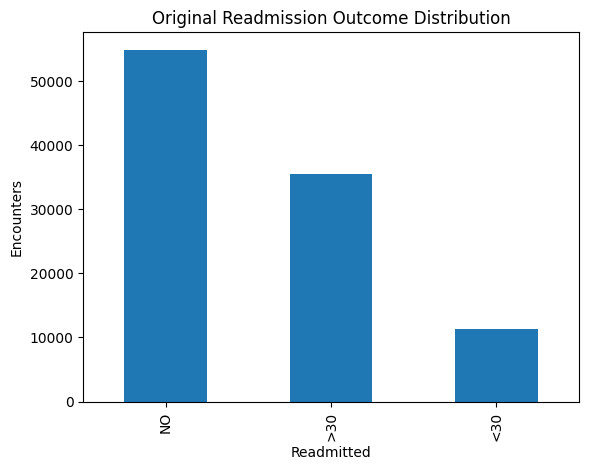

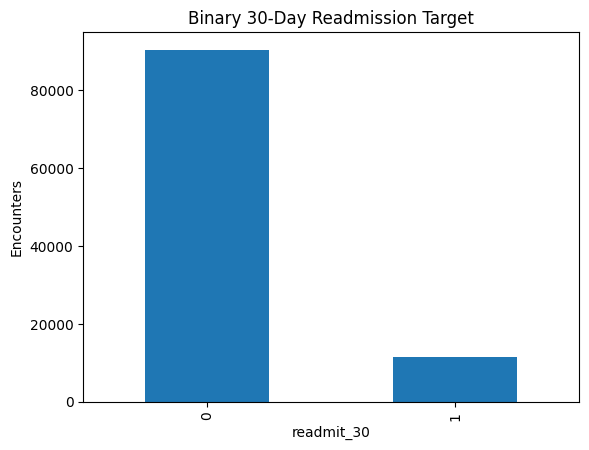

readmit_30
0    0.888401
1    0.111599
Name: proportion, dtype: float64


In [14]:
# 3.1 Original and binary target distributions

fig, ax = plt.subplots()
df["readmitted"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Original Readmission Outcome Distribution")
ax.set_xlabel("Readmitted")
ax.set_ylabel("Encounters")
plt.show()

fig, ax = plt.subplots()
df["readmit_30"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Binary 30-Day Readmission Target")
ax.set_xlabel("readmit_30")
ax.set_ylabel("Encounters")
plt.show()

print(df["readmit_30"].value_counts(normalize=True).rename("proportion"))


### EDA Insight 1 — Target imbalance

The binary target contains **11,357 `<30` readmissions out of 101,766 encounters (11.16%)**. The remaining **88.84%** are negative after combining `>30` and `NO`. Therefore, plain accuracy could look high even for a model that performs poorly on the minority readmission class. The later comparison will emphasize ROC-AUC, PR-AUC, recall, precision, F1/F2, balanced accuracy, and confusion matrices.


### EDA Insight 1 — Target imbalance
The `<30` positive class represents approximately **11.16%** of all encounters. Because the negative class is much larger, accuracy alone could appear high even for a model that performs poorly on early readmissions. The project therefore emphasizes imbalance-aware metrics including PR-AUC, recall, F1/F2, ROC-AUC, and balanced accuracy.


In [15]:
# 3.2 Numerical feature exploration

numerical_candidates = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]

display(df[numerical_candidates].describe().T)

# Focused visualisations are provided in subsequent EDA cells where they add interpretive value.


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


In [16]:
# 3.3 Categorical / demographic exploration

categorical_candidates = [
    "race", "gender", "age", "medical_specialty",
    "admission_type_id", "discharge_disposition_id", "admission_source_id"
]

for col in categorical_candidates:
    if col in df.columns:
        print(f"\n--- {col} ---")
        display(df[col].value_counts(dropna=False).head(20))


--- race ---


,count
race,
Caucasian,76099
AfricanAmerican,19210
?,2273
Hispanic,2037
Other,1506
Asian,641



--- gender ---


,count
gender,
Female,54708
Male,47055
Unknown/Invalid,3



--- age ---


...

,count
admission_type_id,
1,53990
3,18869
2,18480
6,5291
5,4785
8,320
7,21
4,10



--- discharge_disposition_id ---


,count
discharge_disposition_id,
1,60234
3,13954
6,12902
18,3691
2,2128
22,1993
11,1642
5,1184
25,989



--- admission_source_id ---


,count
admission_source_id,
7,57494
1,29565
17,6781
4,3187
6,2264
2,1104
5,855
3,187
20,161


In [17]:
# 3.4 Readmission rates for selected features

def readmission_rate_table(data, col, min_count=1):
    out = (
        data.groupby(col, dropna=False)["readmit_30"]
        .agg(["count", "sum", "mean"])
        .rename(columns={"sum": "readmit_30_count", "mean": "readmit_30_rate"})
        .sort_values("readmit_30_rate", ascending=False)
    )
    return out[out["count"] >= min_count]

# Example:
display(readmission_rate_table(df, "age"))
# Additional focused comparisons are provided only for features with meaningful business/ML relevance.


,count,readmit_30_count,readmit_30_rate
age,,,
[20-30),1657,236,0.142426
[80-90),17197,2078,0.120835
[70-80),26068,3069,0.117731
[30-40),3775,424,0.112318
[60-70),22483,2502,0.111284
[90-100),2793,310,0.110992
[40-50),9685,1027,0.106040
[50-60),17256,1668,0.096662
[10-20),691,40,0.057887


,count,readmit_30_rate
number_inpatient,,
0,67630,0.084371
1,19521,0.129245
2,7566,0.174333
3,3411,0.202873
4,1622,0.236128
5,812,0.314039
6,480,0.345833
7,268,0.354478
8,151,0.443709


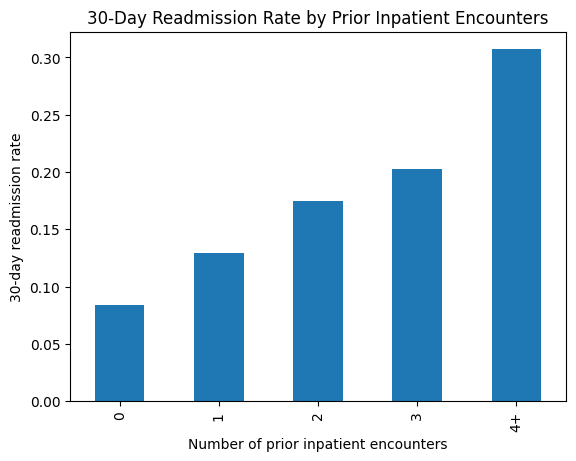

,count,mean
prior_inpatient_group,,
0,67630,0.084371
1,19521,0.129245
2,7566,0.174333
3,3411,0.202873
4+,3638,0.307037


In [18]:

# 3.5 Focused first EDA: prior inpatient utilisation and 30-day readmission

inpatient_rate = (
    df.groupby("number_inpatient")["readmit_30"]
      .agg(["count", "mean"])
      .rename(columns={"mean": "readmit_30_rate"})
)

display(inpatient_rate)

# For visualization, group rare high counts to avoid an unreadable chart.
df_eda = df.copy()

# Defensive numeric conversion before interval binning.
df_eda["number_inpatient"] = pd.to_numeric(
    df_eda["number_inpatient"], errors="coerce"
)

df_eda["prior_inpatient_group"] = pd.cut(
    df_eda["number_inpatient"],
    bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=["0", "1", "2", "3", "4+"]
)

grouped = (
    df_eda.groupby("prior_inpatient_group", observed=False)["readmit_30"]
          .agg(["count", "mean"])
)

fig, ax = plt.subplots()
grouped["mean"].plot(kind="bar", ax=ax)
ax.set_title("30-Day Readmission Rate by Prior Inpatient Encounters")
ax.set_xlabel("Number of prior inpatient encounters")
ax.set_ylabel("30-day readmission rate")
plt.show()

display(grouped)



### EDA Insight 2 — Prior inpatient utilisation

A strong descriptive pattern appears in prior inpatient utilisation. Encounters with `number_inpatient = 0` have an observed `<30` readmission rate of about **8.44%**, compared with **12.92%** for one prior inpatient encounter, **17.43%** for two, **20.29%** for three, and progressively higher rates in several larger-count groups. The highest-count categories contain few observations, so their individual percentages should not be over-interpreted.

This makes `number_inpatient` an important candidate predictor and suggests that prior healthcare utilisation deserves further feature-engineering investigation. This is an association observed in the dataset, not a causal conclusion.


In [19]:

# 3.6 First-pass treatment-pattern EDA
# Formal statistical testing is reserved for Member 4.

for col in ["change", "diabetesMed", "insulin"]:
    table = (
        df.groupby(col)["readmit_30"]
          .agg(["count", "sum", "mean"])
          .rename(columns={"sum": "readmit_30_count", "mean": "readmit_30_rate"})
    )
    print(f"\n{col}")
    display(table)



change


,count,readmit_30_count,readmit_30_rate
change,,,
Ch,47011,5558,0.118228
No,54755,5799,0.105908



diabetesMed


,count,readmit_30_count,readmit_30_rate
diabetesMed,,,
No,23403,2246,0.095971
Yes,78363,9111,0.116267



insulin


,count,readmit_30_count,readmit_30_rate
insulin,,,
Down,12218,1698,0.138975
No,47383,4756,0.100374
Steady,30849,3433,0.111284
Up,11316,1470,0.129905



### EDA Insight 3 — Medication/treatment variables merit secondary analysis

The first-pass EDA shows differences in observed `<30` readmission rates across `change`, `diabetesMed`, and `insulin` categories. These descriptive differences justify the planned secondary medication/treatment analysis, but they do **not** establish statistical significance, practical importance, or causality. Member 4 will later quantify the associations using appropriate tests and effect sizes.



## 3.7 Demographic EDA

The demographic analysis is descriptive. Differences in observed rates should not be interpreted as causal effects or as evidence that demographic characteristics should independently determine care.


,count,readmit_30_rate
age,,
[0-10),161,0.018634
[10-20),691,0.057887
[20-30),1657,0.142426
[30-40),3775,0.112318
[40-50),9685,0.106040
[50-60),17256,0.096662
[60-70),22483,0.111284
[70-80),26068,0.117731
[80-90),17197,0.120835


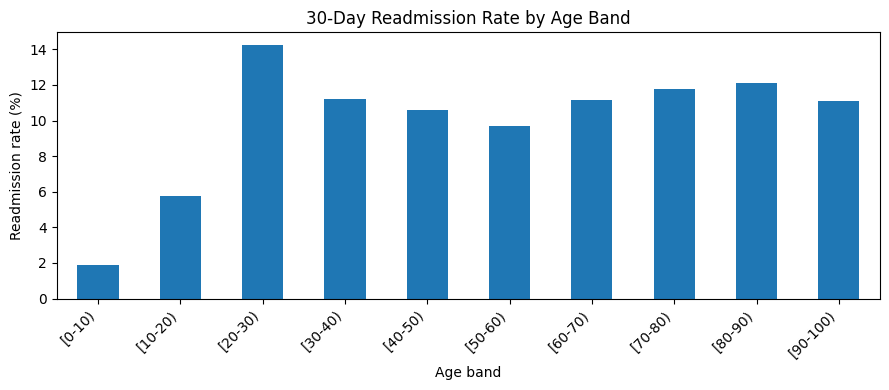

In [20]:

# 3.7.1 Age distribution and 30-day readmission rate

age_order = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)",
    "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"
]

age_summary = (
    df_eda.groupby("age", observed=False)["readmit_30"]
          .agg(["count", "mean"])
          .reindex(age_order)
          .rename(columns={"mean": "readmit_30_rate"})
)

display(age_summary)

fig, ax = plt.subplots(figsize=(9, 4))
(age_summary["readmit_30_rate"] * 100).plot(kind="bar", ax=ax)
ax.set_title("30-Day Readmission Rate by Age Band")
ax.set_xlabel("Age band")
ax.set_ylabel("Readmission rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



### EDA Insight 4 — Age

Readmission rates vary across age bands, but the pattern is not simply linear. The very young groups contain relatively few encounters, while most records are concentrated in the older age bands. For example, the observed rate is about **9.67% for ages 50–60**, **11.73% for 70–80**, and **12.08% for 80–90**. The 20–30 band has a higher observed rate (**14.24%**) but contains only 1,657 encounters. Age should therefore be retained as potentially useful information, while group size and non-linearity should be considered during modelling.



gender


,count,readmit_30_rate
gender,,
Female,54708,0.112452
Male,47055,0.110615
Unknown/Invalid,3,0.000000



race


,count,readmit_30_rate
race,,
Caucasian,76099,0.112906
AfricanAmerican,19210,0.112181
?,2273,0.082710
Hispanic,2037,0.104075
Other,1506,0.096282
Asian,641,0.101404


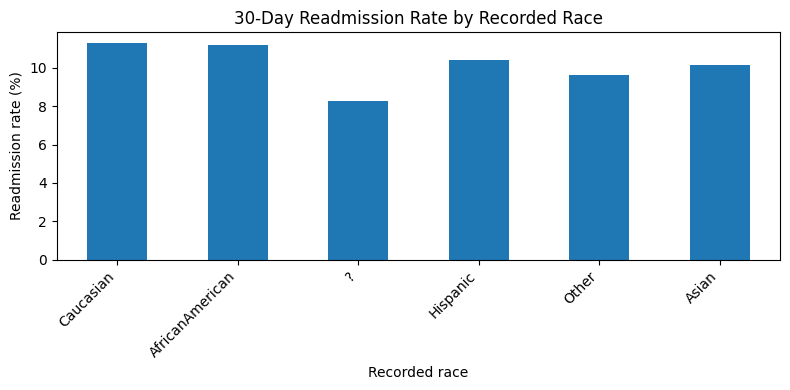

In [21]:

# 3.7.2 Gender and race: counts and readmission rates

for col in ["gender", "race"]:
    summary = (
        df_eda.groupby(col, dropna=False)["readmit_30"]
              .agg(["count", "mean"])
              .rename(columns={"mean": "readmit_30_rate"})
              .sort_values("count", ascending=False)
    )
    print(f"\n{col}")
    display(summary)

race_summary = (
    df_eda.groupby("race", dropna=False)["readmit_30"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "readmit_30_rate"})
          .sort_values("count", ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 4))
(race_summary["readmit_30_rate"] * 100).plot(kind="bar", ax=ax)
ax.set_title("30-Day Readmission Rate by Recorded Race")
ax.set_xlabel("Recorded race")
ax.set_ylabel("Readmission rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



### EDA Insight 5 — Gender and recorded race

Female and male encounters have very similar observed `<30` rates (**11.25%** and **11.06%**). Recorded race categories also show relatively modest descriptive differences among the larger groups, while the missing/`?` category has a lower observed rate and must not be interpreted as a meaningful demographic group. These variables require cautious treatment because they may relate to fairness and data-collection processes as well as prediction.



## 3.8 Healthcare Utilisation EDA

Prior utilisation is especially relevant because it summarizes earlier contact with inpatient, emergency, and outpatient services.


,group,count,mean,feature
0,0,67630,0.084371,number_inpatient
1,1,19521,0.129245,number_inpatient
2,2,7566,0.174333,number_inpatient
3,3,3411,0.202873,number_inpatient
4,4+,3638,0.307037,number_inpatient
5,0,90383,0.104743,number_emergency
6,1,7677,0.143546,number_emergency
7,2,2042,0.182664,number_emergency
8,3,725,0.202759,number_emergency
9,4+,939,0.285410,number_emergency


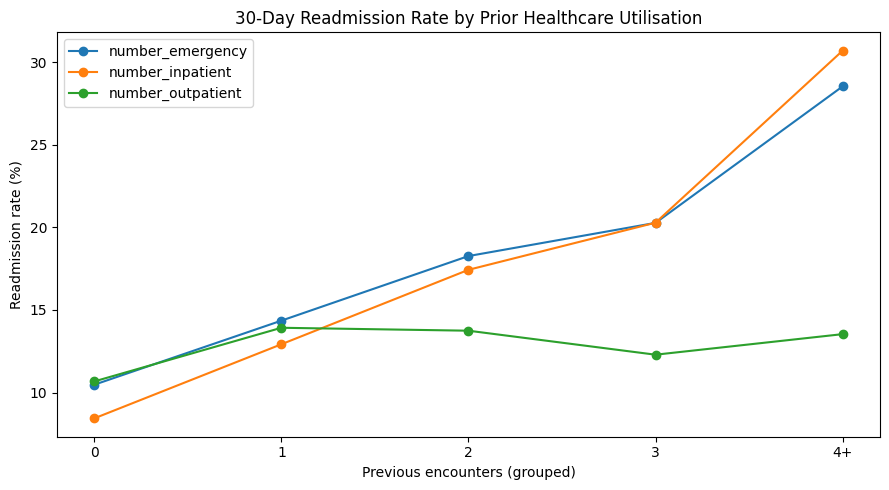

In [22]:

# 3.8.1 Compare prior inpatient, emergency and outpatient utilisation

def utilisation_group(series):
    # pd.cut requires a consistently numeric input.
    series = pd.to_numeric(series, errors="coerce")
    return pd.cut(
        series,
        bins=[-1, 0, 1, 2, 3, float("inf")],
        labels=["0", "1", "2", "3", "4+"]
    )

utilisation_rows = []
for col in ["number_inpatient", "number_emergency", "number_outpatient"]:
    grouped = utilisation_group(df_eda[col])
    temp = (
        pd.DataFrame({"group": grouped, "readmit_30": df_eda["readmit_30"]})
        .groupby("group", observed=False)["readmit_30"]
        .agg(["count", "mean"])
        .reset_index()
    )
    temp["feature"] = col
    utilisation_rows.append(temp)

utilisation_summary = pd.concat(utilisation_rows, ignore_index=True)
display(utilisation_summary)

fig, ax = plt.subplots(figsize=(9, 5))
for feature, temp in utilisation_summary.groupby("feature"):
    ax.plot(
        temp["group"].astype(str),
        temp["mean"] * 100,
        marker="o",
        label=feature
    )
ax.set_title("30-Day Readmission Rate by Prior Healthcare Utilisation")
ax.set_xlabel("Previous encounters (grouped)")
ax.set_ylabel("Readmission rate (%)")
ax.legend()
plt.tight_layout()
plt.show()



### EDA Insight 6 — Prior utilisation

Prior inpatient and emergency utilisation show the clearest risk gradients. The `<30` rate rises from **8.44% to 30.70%** between zero and 4+ prior inpatient encounters, and from **10.47% to 28.54%** between zero and 4+ prior emergency encounters. Outpatient utilisation shows a weaker and less monotonic pattern. These findings make previous inpatient/emergency use strong candidates for the modelling feature set and for Member 3's utilisation feature engineering.



## 3.9 Hospital-Stay and Clinical-Intensity Variables


,count,readmit_30_rate
time_in_hospital,,
1,14208,0.081785
2,17224,0.099396
3,17756,0.106668
4,13924,0.118070
5,9966,0.120309
6,7539,0.125879
7,5859,0.128350
8,4391,0.142337
9,3002,0.137242


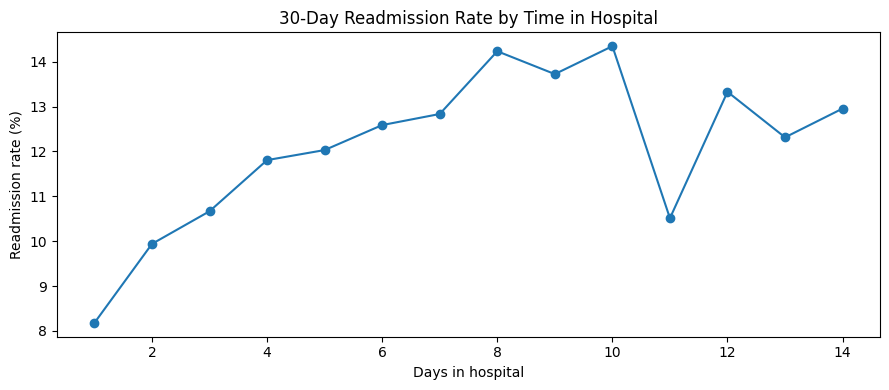

In [23]:

# 3.9.1 Time in hospital

stay_summary = (
    df_eda.groupby("time_in_hospital")["readmit_30"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "readmit_30_rate"})
)

display(stay_summary)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(stay_summary.index, stay_summary["readmit_30_rate"] * 100, marker="o")
ax.set_title("30-Day Readmission Rate by Time in Hospital")
ax.set_xlabel("Days in hospital")
ax.set_ylabel("Readmission rate (%)")
plt.tight_layout()
plt.show()


Medication burden


,count,mean
med_group,,
1–10,25861,0.090638
11–15,29384,0.109107
16–20,22641,0.121726
21+,23880,0.127764


Number of diagnoses


,count,readmit_30_rate
number_diagnoses,,
1,219,0.059361
2,1023,0.060606
3,2835,0.073721
4,5537,0.082536
5,11393,0.091547
6,10161,0.104124
7,10393,0.107669
8,10616,0.118124
9,49474,0.123802


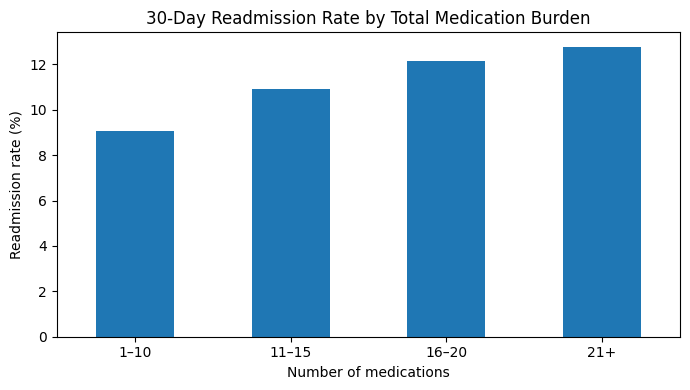

In [24]:

# 3.9.2 Number of medications and number of diagnoses

# Medication-count bins chosen for readable EDA; raw values remain available for modelling.
med_bins = pd.cut(
    df_eda["num_medications"],
    bins=[0, 10, 15, 20, float("inf")],
    labels=["1–10", "11–15", "16–20", "21+"]
)

med_burden_summary = (
    pd.DataFrame({"med_group": med_bins, "readmit_30": df_eda["readmit_30"]})
    .groupby("med_group", observed=False)["readmit_30"]
    .agg(["count", "mean"])
)

diagnosis_summary = (
    df_eda.groupby("number_diagnoses")["readmit_30"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "readmit_30_rate"})
)

print("Medication burden")
display(med_burden_summary)
print("Number of diagnoses")
display(diagnosis_summary)

fig, ax = plt.subplots(figsize=(7, 4))
(med_burden_summary["mean"] * 100).plot(kind="bar", ax=ax)
ax.set_title("30-Day Readmission Rate by Total Medication Burden")
ax.set_xlabel("Number of medications")
ax.set_ylabel("Readmission rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### EDA Insight 7 — Hospital stay and clinical complexity

Longer hospital stays generally show higher observed readmission rates than very short stays, although the pattern is not perfectly monotonic. Medication burden also shows a useful descriptive gradient: encounters with more medications tend to have higher `<30` rates. `number_diagnoses` rises from roughly **6%** at 1–2 diagnoses toward about **12%** around 8–9 diagnoses; categories above 9 are very small and should not be over-interpreted. These variables may capture patient complexity rather than direct causal mechanisms.



## 3.10 Diagnosis EDA

The raw `diag_1`, `diag_2`, and `diag_3` fields contain many ICD-9-style codes and are high-cardinality. For EDA, codes are grouped into broad clinical categories using the grouping logic below. This grouping is an analytical transformation, **not** supplied by `IDS_mapping.csv`, and it must be documented if Member 3 later uses it for feature engineering.


,count,readmit_30_rate
diag_1_group,,
Circulatory,30437,0.114499
Other,16527,0.110123
Respiratory,14423,0.097275
Digestive,9475,0.107124
Diabetes,8757,0.129839
Injury,6974,0.122455
Genitourinary,5117,0.108462
Musculoskeletal,4957,0.095017
Neoplasms,3433,0.100786


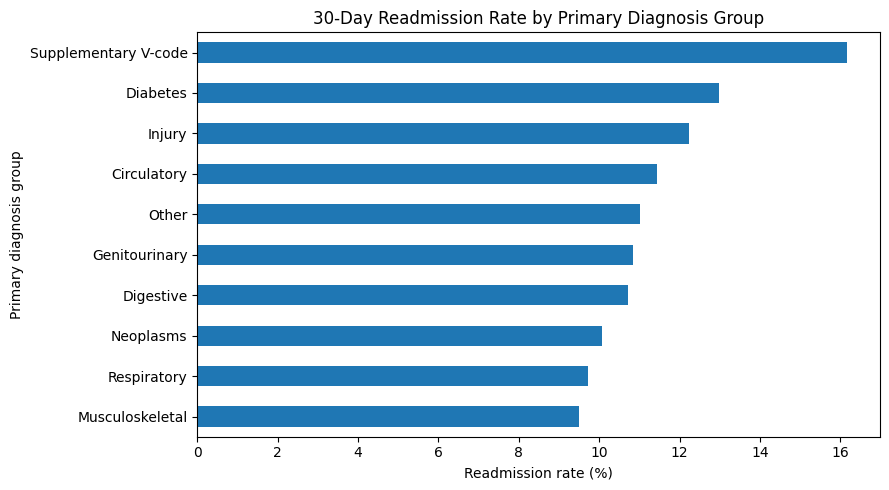

In [25]:

# 3.10.1 Broad ICD-9-style diagnosis grouping for EDA

def diagnosis_group(value):
    if pd.isna(value) or str(value) == "?":
        return "Missing / unknown"

    code = str(value)

    if code.startswith("V"):
        return "Supplementary V-code"
    if code.startswith("E"):
        return "External cause E-code"

    try:
        number = float(code)
    except ValueError:
        return "Other / unknown"

    if 390 <= number <= 459 or number == 785:
        return "Circulatory"
    if 460 <= number <= 519 or number == 786:
        return "Respiratory"
    if 520 <= number <= 579 or number == 787:
        return "Digestive"
    if 250 <= number < 251:
        return "Diabetes"
    if 800 <= number <= 999:
        return "Injury"
    if 710 <= number <= 739:
        return "Musculoskeletal"
    if 580 <= number <= 629 or number == 788:
        return "Genitourinary"
    if 140 <= number <= 239:
        return "Neoplasms"

    return "Other"

for col in ["diag_1", "diag_2", "diag_3"]:
    df_eda[f"{col}_group"] = df_eda[col].map(diagnosis_group)

diag1_summary = (
    df_eda.groupby("diag_1_group")["readmit_30"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "readmit_30_rate"})
          .sort_values("count", ascending=False)
)
display(diag1_summary)

fig, ax = plt.subplots(figsize=(9, 5))
plot_diag = diag1_summary[diag1_summary["count"] >= 500].sort_values("readmit_30_rate")
(plot_diag["readmit_30_rate"] * 100).plot(kind="barh", ax=ax)
ax.set_title("30-Day Readmission Rate by Primary Diagnosis Group")
ax.set_xlabel("Readmission rate (%)")
ax.set_ylabel("Primary diagnosis group")
plt.tight_layout()
plt.show()


In [26]:

# 3.10.2 Secondary and tertiary diagnosis-group summaries

for col in ["diag_2_group", "diag_3_group"]:
    summary = (
        df_eda.groupby(col)["readmit_30"]
              .agg(["count", "mean"])
              .rename(columns={"mean": "readmit_30_rate"})
              .sort_values("count", ascending=False)
    )
    print(f"\n{col}")
    display(summary)



diag_2_group


,count,readmit_30_rate
diag_2_group,,
Circulatory,31881,0.111007
Other,24017,0.112795
Diabetes,12794,0.105831
Respiratory,10895,0.105186
Genitourinary,8376,0.117598
Digestive,4170,0.114868
Neoplasms,2547,0.149195
Injury,2428,0.114498
Supplementary V-code,1805,0.100831



diag_3_group


,count,readmit_30_rate
diag_3_group,,
Circulatory,30306,0.108064
Other,24137,0.112234
Diabetes,17157,0.105671
Respiratory,7358,0.120549
Genitourinary,6680,0.134581
Digestive,3930,0.119593
Supplementary V-code,3814,0.099895
Injury,1946,0.115622
Musculoskeletal,1915,0.106527



### EDA Insight 8 — Diagnoses

The primary diagnosis is most often circulatory, followed by the broad `Other` and respiratory groups. Primary diabetes-coded encounters have an observed `<30` rate of about **12.98%**, compared with **11.45%** for circulatory and **9.73%** for respiratory encounters. Some smaller groups show higher rates, but category size matters. The raw diagnosis codes are too granular for simple visual interpretation, so Member 3 should compare defensible grouping/encoding strategies rather than treating this EDA grouping as automatically final.


### 3.10.1 Prepare readable ID mappings for Section 3.11

The raw diabetes dataset stores admission type, discharge disposition, and admission source as numeric IDs. Before the descriptive analysis below, these IDs are mapped to their human-readable descriptions from `IDS_mapping.csv`.

This mapping is for interpretation/EDA. It does not alter the original ID columns.


In [27]:
# 3.10.1 Build readable mapping columns safely before Section 3.11
#
# IDS_mapping.csv has a special structure:
# - "admission_type_id" is the FIRST CSV column header.
# - "discharge_disposition_id" and "admission_source_id" appear later as section rows.
# This parser handles both cases.

def extract_ids_mapping(mapping_df, section_name):
    raw = mapping_df.copy()
    first_col = raw.columns[0]
    second_col = raw.columns[1]

    known_sections = {
        "admission_type_id",
        "discharge_disposition_id",
        "admission_source_id"
    }

    # The first section is stored in the CSV header, not as a data row.
    if str(first_col).strip() == section_name:
        start = 0
    else:
        section_rows = raw.index[
            raw[first_col].astype(str).str.strip().eq(section_name)
        ].tolist()

        if not section_rows:
            raise ValueError(
                f"Could not find section '{section_name}' in IDS_mapping.csv"
            )

        start = section_rows[0] + 1

    collected = []

    for i in range(start, len(raw)):
        id_value = str(raw.iloc[i, 0]).strip()
        description = str(raw.iloc[i, 1]).strip()

        # Stop when the next named section begins.
        if id_value in known_sections:
            break

        # Blank separator row ends a section once values have been collected.
        if id_value.lower() in {"", "nan", "none"}:
            if collected:
                break
            continue

        try:
            numeric_id = int(float(id_value))
        except (TypeError, ValueError):
            continue

        # Preserve the mapping description as text.
        if description.lower() in {"nan", "none"}:
            description = "Unknown / unmapped"

        collected.append((numeric_id, description))

    if not collected:
        raise ValueError(
            f"No ID-description rows found for '{section_name}'."
        )

    return dict(collected)


admission_type_map = extract_ids_mapping(
    ids_mapping_raw, "admission_type_id"
)

discharge_disposition_map = extract_ids_mapping(
    ids_mapping_raw, "discharge_disposition_id"
)

admission_source_map = extract_ids_mapping(
    ids_mapping_raw, "admission_source_id"
)


df_eda["admission_type_id_label"] = (
    pd.to_numeric(df_eda["admission_type_id"], errors="coerce")
      .map(admission_type_map)
      .fillna("Unknown / unmapped")
)

df_eda["discharge_disposition_id_label"] = (
    pd.to_numeric(df_eda["discharge_disposition_id"], errors="coerce")
      .map(discharge_disposition_map)
      .fillna("Unknown / unmapped")
)

df_eda["admission_source_id_label"] = (
    pd.to_numeric(df_eda["admission_source_id"], errors="coerce")
      .map(admission_source_map)
      .fillna("Unknown / unmapped")
)


required_label_columns = [
    "admission_type_id_label",
    "discharge_disposition_id_label",
    "admission_source_id_label"
]

assert all(c in df_eda.columns for c in required_label_columns)

print("Readable mapping columns created successfully.")
print("Admission type mappings:", len(admission_type_map))
print("Discharge disposition mappings:", len(discharge_disposition_map))
print("Admission source mappings:", len(admission_source_map))

display(
    df_eda[
        [
            "admission_type_id", "admission_type_id_label",
            "discharge_disposition_id", "discharge_disposition_id_label",
            "admission_source_id", "admission_source_id_label"
        ]
    ].head()
)


Readable mapping columns created successfully.
Admission type mappings: 8
Discharge disposition mappings: 30
Admission source mappings: 25


,admission_type_id,admission_type_id_label,discharge_disposition_id,discharge_disposition_id_label,admission_source_id,admission_source_id_label
0,6,NULL,25,Not Mapped,1,Physician Referral
1,1,Emergency,1,Discharged to home,7,Emergency Room
2,1,Emergency,1,Discharged to home,7,Emergency Room
3,1,Emergency,1,Discharged to home,7,Emergency Room
4,1,Emergency,1,Discharged to home,7,Emergency Room



## 3.11 Admission, Discharge and Source Mappings


,count,readmit_30_rate
admission_type_id_label,,
Emergency,53990,0.115225
Elective,18869,0.103927
Urgent,18480,0.111797
NULL,5291,0.110754
Not Available,4785,0.103448
Not Mapped,320,0.084375
Trauma Center,21,0.000000
Newborn,10,0.100000


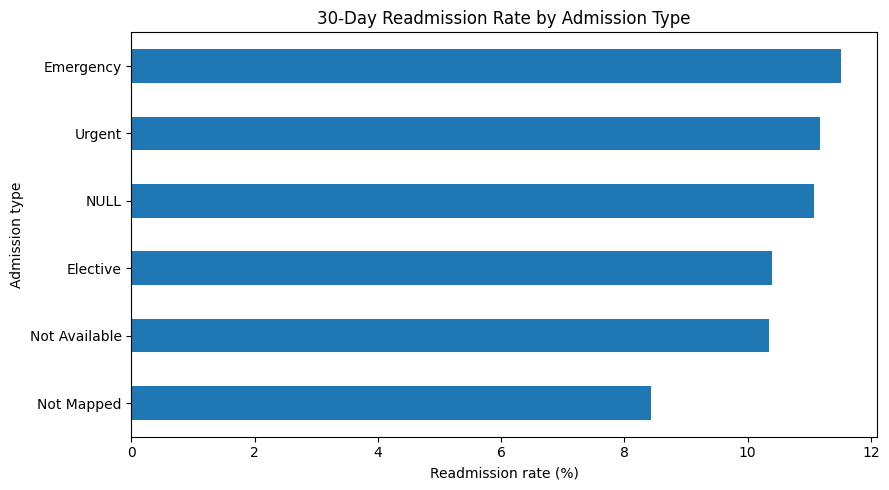

In [28]:

# 3.11.1 Admission type

admission_type_summary = (
    df_eda.groupby("admission_type_id_label")["readmit_30"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "readmit_30_rate"})
          .sort_values("count", ascending=False)
)
display(admission_type_summary)

fig, ax = plt.subplots(figsize=(9, 5))
plot_data = admission_type_summary[admission_type_summary["count"] >= 100]
(plot_data["readmit_30_rate"] * 100).sort_values().plot(kind="barh", ax=ax)
ax.set_title("30-Day Readmission Rate by Admission Type")
ax.set_xlabel("Readmission rate (%)")
ax.set_ylabel("Admission type")
plt.tight_layout()
plt.show()


,count,readmit_30_rate
admission_source_id_label,,
Emergency Room,57494,0.116882
Physician Referral,29565,0.105868
NULL,6781,0.104114
Transfer from a hospital,3187,0.096956
Transfer from another health care facility,2264,0.093640
Clinic Referral,1104,0.100543
Transfer from a Skilled Nursing Facility (SNF),855,0.118129
HMO Referral,187,0.155080
Not Mapped,161,0.136646


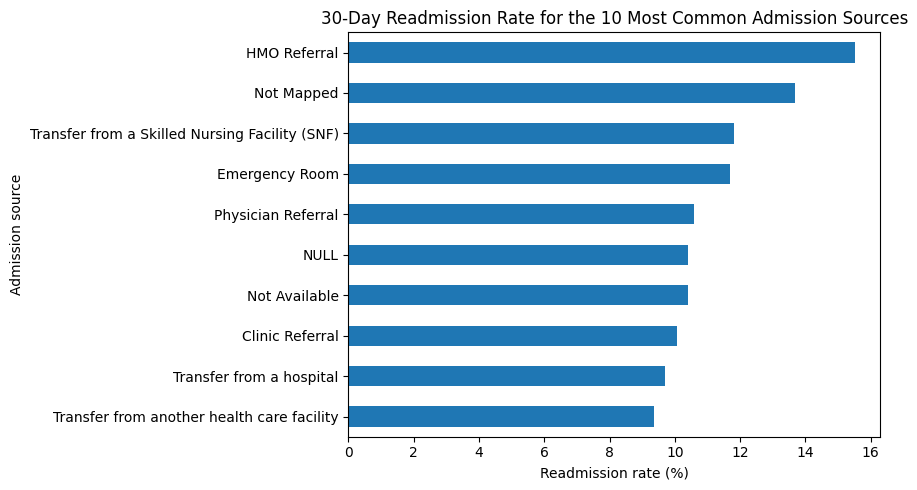

In [29]:

# 3.11.2 Admission source — show common categories

admission_source_summary = (
    df_eda.groupby("admission_source_id_label")["readmit_30"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "readmit_30_rate"})
          .sort_values("count", ascending=False)
)

display(admission_source_summary.head(15))

fig, ax = plt.subplots(figsize=(9, 5))
top_sources = admission_source_summary.head(10).sort_values("readmit_30_rate")
(top_sources["readmit_30_rate"] * 100).plot(kind="barh", ax=ax)
ax.set_title("30-Day Readmission Rate for the 10 Most Common Admission Sources")
ax.set_xlabel("Readmission rate (%)")
ax.set_ylabel("Admission source")
plt.tight_layout()
plt.show()


,count,readmit_30_rate
discharge_disposition_id_label,,
Discharged to home,60234,0.093004
Discharged/transferred to SNF,13954,0.146625
Discharged/transferred to home with home health service,12902,0.126957
NULL,3691,0.124357
Discharged/transferred to another short term hospital,2128,0.160714
Discharged/transferred to another rehab fac including rehab units of a hospital .,1993,0.276969
Expired,1642,0.000000
Discharged/transferred to another type of inpatient care institution,1184,0.208615
Not Mapped,989,0.093023


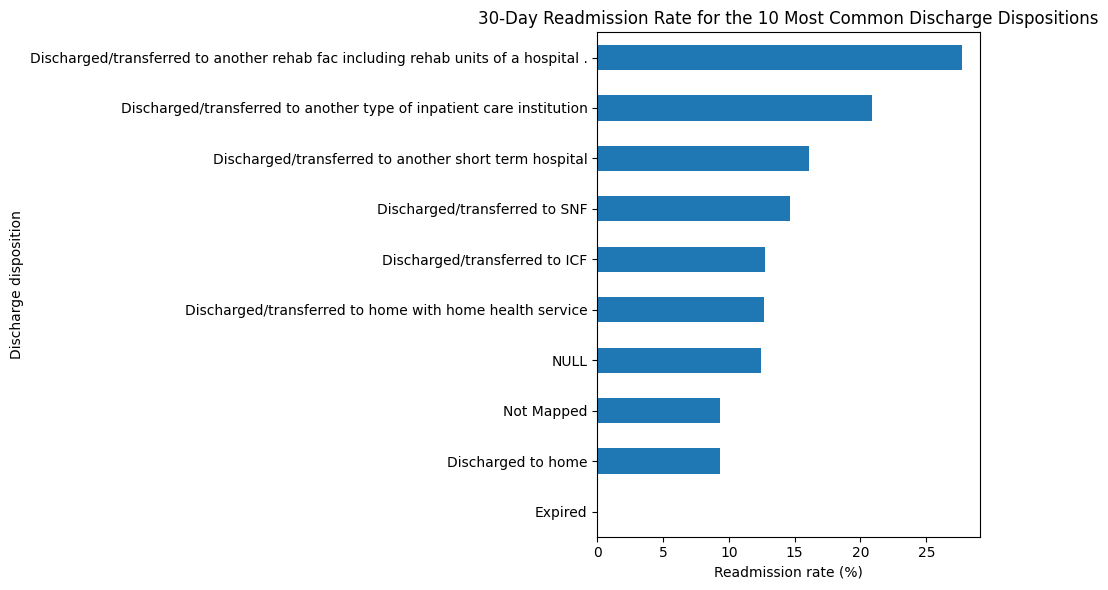

In [30]:

# 3.11.3 Discharge disposition — EDA only, NOT automatically approved for modelling

discharge_summary = (
    df_eda.groupby("discharge_disposition_id_label")["readmit_30"]
          .agg(["count", "mean"])
          .rename(columns={"mean": "readmit_30_rate"})
          .sort_values("count", ascending=False)
)

display(discharge_summary.head(15))

fig, ax = plt.subplots(figsize=(10, 6))
top_discharge = discharge_summary.head(10).sort_values("readmit_30_rate")
(top_discharge["readmit_30_rate"] * 100).plot(kind="barh", ax=ax)
ax.set_title("30-Day Readmission Rate for the 10 Most Common Discharge Dispositions")
ax.set_xlabel("Readmission rate (%)")
ax.set_ylabel("Discharge disposition")
plt.tight_layout()
plt.show()



### EDA Insight 9 — Administrative mappings and leakage warning

The mapping file makes the coded admission/source/discharge variables interpretable and reveals that these categories contain potentially useful context. However, **discharge disposition needs special caution**. Categories such as hospice or expired describe outcomes at discharge and can structurally affect whether a later readmission can occur. Member 2 must therefore perform a formal prediction-time and leakage review before this feature is used. EDA usefulness alone is not sufficient reason to include a variable in a predictive model.



## 3.12 Medication/Treatment Pattern EDA

This section remains descriptive. Formal hypothesis tests, effect sizes, odds ratios, and integrated medication interpretation belong to Member 4.



change


,count,readmit_30_count,readmit_30_rate
change,,,
Ch,47011,5558,0.118228
No,54755,5799,0.105908



diabetesMed


,count,readmit_30_count,readmit_30_rate
diabetesMed,,,
Yes,78363,9111,0.116267
No,23403,2246,0.095971



insulin


,count,readmit_30_count,readmit_30_rate
insulin,,,
Down,12218,1698,0.138975
Up,11316,1470,0.129905
Steady,30849,3433,0.111284
No,47383,4756,0.100374


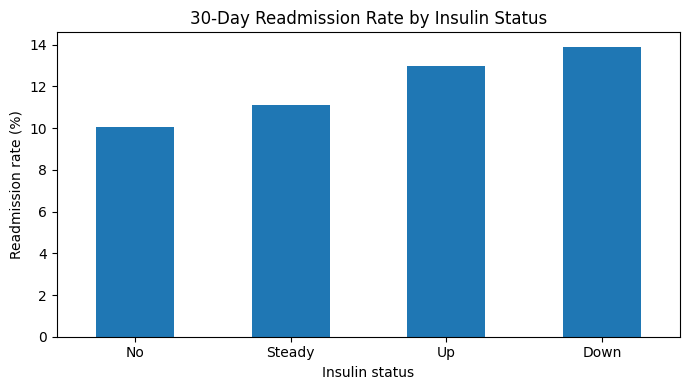

In [31]:

# 3.12.1 Core treatment variables

medication_summaries = {}

for col in ["change", "diabetesMed", "insulin"]:
    summary = (
        df_eda.groupby(col)["readmit_30"]
              .agg(["count", "sum", "mean"])
              .rename(columns={"sum": "readmit_30_count", "mean": "readmit_30_rate"})
              .sort_values("readmit_30_rate", ascending=False)
    )
    medication_summaries[col] = summary
    print(f"\n{col}")
    display(summary)

fig, ax = plt.subplots(figsize=(7, 4))
insulin_plot = medication_summaries["insulin"].reindex(["No", "Steady", "Up", "Down"])
(insulin_plot["readmit_30_rate"] * 100).plot(kind="bar", ax=ax)
ax.set_title("30-Day Readmission Rate by Insulin Status")
ax.set_xlabel("Insulin status")
ax.set_ylabel("Readmission rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [32]:

# 3.12.2 Individual diabetes-medication fields: prevalence and readmission rates

medication_columns = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide", "examide",
    "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone"
]

medication_profile = []
for col in medication_columns:
    if col not in df_eda.columns:
        continue
    active = df_eda[col].astype(str).ne("No")
    medication_profile.append({
        "medication": col,
        "active_encounters": int(active.sum()),
        "active_pct": 100 * active.mean(),
        "readmit_rate_when_active": df_eda.loc[active, "readmit_30"].mean()
            if active.any() else np.nan
    })

medication_profile = (
    pd.DataFrame(medication_profile)
      .sort_values("active_encounters", ascending=False)
)

display(medication_profile)


,medication,active_encounters,active_pct,readmit_rate_when_active
17,insulin,54383,53.439263,0.121380
0,metformin,19988,19.641138,0.097008
6,glipizide,12686,12.465853,0.114457
7,glyburide,10650,10.465185,0.106291
9,pioglitazone,7328,7.200833,0.105622
10,rosiglitazone,6365,6.254545,0.104478
4,glimepiride,5191,5.100918,0.102100
1,repaglinide,1539,1.512293,0.133203
18,glyburide-metformin,706,0.693748,0.110482
2,nateglinide,703,0.690800,0.113798



### EDA Insight 10 — Medication patterns

The descriptive treatment variables support the planned secondary lens. Encounters with a recorded diabetes-medication change have an observed `<30` rate of **11.82%**, versus **10.59%** with no change. Encounters marked `diabetesMed = Yes` show **11.63%**, versus **9.60%** for `No`. Insulin status shows a clearer ordered descriptive difference: approximately **10.04% (`No`)**, **11.13% (`Steady`)**, **12.99% (`Up`)**, and **13.90% (`Down`)**. These patterns justify Member 4's formal analysis, but they may reflect underlying severity or treatment complexity and must not be interpreted as medication changes causing readmission.



## 3.13 EDA Summary Before Preprocessing

Member 1's EDA establishes the following priorities for the next stages:

1. The target is substantially imbalanced, so evaluation must go beyond accuracy.
2. Repeated patients create a real leakage risk and motivate a patient-aware split investigation.
3. Missingness is substantial and is explicitly represented by `?`; the literal `None` laboratory category is preserved.
4. Some variables (`examide`, `citoglipton`) appear to have no predictive variation.
5. Prior inpatient and emergency utilisation show strong descriptive relationships with `<30` readmission.
6. Hospital-stay/complexity variables such as medication count and diagnosis count show potentially useful patterns.
7. Raw diagnosis codes are high-cardinality and require a justified modelling strategy.
8. Administrative ID mappings improve interpretability, while discharge disposition requires explicit leakage review.
9. Medication/treatment variables show descriptive differences that justify the planned secondary analysis.
10. Demographic variables should be handled carefully, including later fairness/subgroup evaluation where feasible.

No feature is retained, removed, imputed, encoded, or transformed for modelling solely because of EDA. Those decisions are documented in Members 2 and 3.


## 4. EDA Insight Log — Member 1 Complete

| ID | Finding | Evidence from uploaded dataset | Modelling implication | Owner |
|---|---|---|---|---|
| EDA-01 | `<30` is a minority outcome | 11,357 / 101,766 = **11.16%** | Use imbalance-aware metrics and strategy | Member 1 |
| EDA-02 | Explicit missingness is substantial in several fields | `weight` has 98,569 `?`; `medical_specialty` 49,949 `?`; `payer_code` 40,256 `?`; literal `None` lab categories are preserved | Member 2 must define a documented missing-data policy | Member 1 |
| EDA-03 | Repeated patients are material | 71,518 unique patients; 16,773 patients repeat; 46.21% of encounters belong to repeating patients | Investigate patient-group-aware splitting | Member 1 |
| EDA-04 | Exact row/encounter duplicates are not the issue | 0 exact duplicate rows; 0 duplicate `encounter_id` values | Do not confuse repeated patients with duplicate rows | Member 1 |
| EDA-05 | Some features appear constant | `examide` and `citoglipton` each show one observed category | Review for removal as zero-information predictors | Member 1 |
| EDA-06 | Prior inpatient utilisation has a strong descriptive gradient | `<30` rate: 0 = 8.44%, 1 = 12.92%, 2 = 17.43%, 3 = 20.29%, 4+ = 30.70% | Strong candidate predictor; consider utilisation feature engineering | Member 1 |
| EDA-07 | Prior emergency utilisation also shows a gradient | `<30` rate: 0 = 10.47%, 1 = 14.35%, 2 = 18.27%, 3 = 20.28%, 4+ = 28.54% | Retain/investigate utilisation signal | Member 1 |
| EDA-08 | Outpatient utilisation is weaker/non-monotonic | 0 = 10.67%, 1 = 13.92%, 2 = 13.75%, 3 = 12.29%, 4+ = 13.54% | May add information but should not be assumed equivalent to inpatient use | Member 1 |
| EDA-09 | Age has non-linear descriptive differences | Most data are older adults; 50–60 ≈ 9.67%, 70–80 ≈ 11.77%, 80–90 ≈ 12.08% | Preserve age ordering/information; avoid assuming linearity | Member 1 |
| EDA-10 | Gender rates are very similar | Female ≈ 11.25%, Male ≈ 11.06% | Evaluate rather than assume strong predictive value | Member 1 |
| EDA-11 | Hospital/clinical complexity variables show useful patterns | Longer stays, more medications, and more diagnoses often correspond to higher observed rates | Retain for preprocessing/model evaluation | Member 1 |
| EDA-12 | Diagnosis fields are high-cardinality | Broad primary groups show different rates; raw codes contain many categories | Member 3 should compare defensible grouping/encoding strategies | Member 1 |
| EDA-13 | ID mappings add interpretable hospital context | Admission type/source/discharge labels recovered from `IDS_mapping.csv` | Use mappings for interpretation; decide modelling representation later | Member 1 |
| EDA-14 | Discharge disposition is a leakage/availability concern | It encodes discharge outcomes such as home, hospice, transfer, expired | Formal Member 2 leakage review required before modelling | Member 1 |
| EDA-15 | Medication change shows a descriptive difference | `Ch` ≈ 11.82% vs `No` ≈ 10.59% | Formal association/effect-size analysis in Member 4 | Member 1 |
| EDA-16 | Diabetes medication status shows a descriptive difference | `Yes` ≈ 11.63% vs `No` ≈ 9.60% | Secondary analysis + model importance comparison | Member 1 |
| EDA-17 | Insulin status shows treatment-pattern differences | No ≈ 10.04%, Steady ≈ 11.13%, Up ≈ 12.99%, Down ≈ 13.90% | Formal Member 4 analysis; do not infer causality | Member 1 |
| EDA-18 | Demographic findings need cautious interpretation | Race includes a missing `?` category and some small groups | Later subgroup/fairness checks where sample sizes permit | Member 1 |

### Member 1 EDA hand-off

The EDA is now sufficient to hand the project to **Member 2 for leakage review, patient-aware splitting, missing-value policy, encoding/scaling decisions, and the shared preprocessing architecture**. Member 3 will later formalize feature engineering, and Member 4 will perform inferential medication/treatment analysis.

---
# PART 2 — LEAKAGE REVIEW, DATA SPLITTING & PREPROCESSING

**Owner: Member 2 — De Silva N.S.R.**



## 6. Leakage and Prediction-Time Feature Review

The project predicts `<30` readmission using information intended to be available at or before discharge. A feature is therefore not accepted merely because it exists in the dataset.

### Leakage/eligibility decisions

| Feature / group | Decision | Reason |
|---|---|---|
| `readmitted` | **DROP** | Source label used to construct `readmit_30`; direct target leakage |
| `encounter_id` | **DROP from predictors** | Unique record identifier; no clinical meaning |
| `patient_nbr` | **DROP from predictors, KEEP for grouping** | Patient identifier; required to prevent patient overlap across splits |
| `discharge_disposition_id` | **DROP from primary model** | Contains discharge-outcome states such as hospice/expired and can structurally affect the possibility of later readmission; high target-proxy/deployment risk |
| `weight` | **DROP** | 98,569 / 101,766 values are `?` (~96.9% missing), leaving too little observed information for a defensible primary model |
| `examide`, `citoglipton` | **DROP** | Constant in the uploaded dataset; zero predictive variation |
| Admission type/source | **KEEP** | Administrative context available by the encounter/discharge workflow; no direct target encoding identified |
| Demographics | **KEEP with caution** | Potential predictive/fairness relevance; later subgroup evaluation required |
| Diagnosis, utilisation, stay, lab-result categories, medications | **KEEP pending feature engineering** | Relevant encounter information; no direct target field identified in this review |

> **Conservative modelling choice:** `discharge_disposition_id` is excluded from the primary model even though disposition is known at discharge. This avoids letting terminal/hospice/disposition states act as a structural proxy for whether readmission can occur. A later sensitivity analysis could test the effect of this exclusion if the group wants to document it.


In [33]:

# 6.1 Programmatic leakage / eligibility table

leakage_review = pd.DataFrame([
    ["readmitted", "DROP", "Original outcome used to create readmit_30", "No"],
    ["encounter_id", "DROP predictor", "Unique encounter identifier", "Yes"],
    ["patient_nbr", "GROUP ONLY", "Used to keep each patient in exactly one split", "Yes"],
    ["discharge_disposition_id", "DROP", "Potential target proxy / structural post-discharge eligibility concern", "At discharge"],
    ["weight", "DROP", "Approximately 96.9% explicit '?' missingness", "Yes"],
    ["examide", "DROP", "Constant feature", "Yes"],
    ["citoglipton", "DROP", "Constant feature", "Yes"],
], columns=["feature", "decision", "reason", "availability"])

display(leakage_review)


,feature,decision,reason,availability
0,readmitted,DROP,Original outcome used to create readmit_30,No
1,encounter_id,DROP predictor,Unique encounter identifier,Yes
2,patient_nbr,GROUP ONLY,Used to keep each patient in exactly one split,Yes
3,discharge_disposition_id,DROP,Potential target proxy / structural post-disch...,At discharge
4,weight,DROP,Approximately 96.9% explicit '?' missingness,Yes
5,examide,DROP,Constant feature,Yes
6,citoglipton,DROP,Constant feature,Yes


In [34]:

# 6.2 Verify the key decisions against the uploaded dataset

explicit_missing = (df.astype(str) == "?").sum()

checks = pd.DataFrame({
    "feature": ["weight", "examide", "citoglipton"],
    "question_mark_count": [
        explicit_missing.get("weight", 0),
        explicit_missing.get("examide", 0),
        explicit_missing.get("citoglipton", 0),
    ],
    "n_unique_including_question_mark": [
        df["weight"].nunique(dropna=False),
        df["examide"].nunique(dropna=False),
        df["citoglipton"].nunique(dropna=False),
    ]
})
display(checks)

print("Weight '?' percentage:",
      round(100 * explicit_missing["weight"] / len(df), 2), "%")


,feature,question_mark_count,n_unique_including_question_mark
0,weight,98569,10
1,examide,0,1
2,citoglipton,0,1


Weight '?' percentage: 96.86 %



### Leakage Review Decision

The most important leakage control is not only column removal. Because **the same patient can have multiple encounters**, a conventional row-wise random split could place one patient's earlier/later encounters in different subsets. The evaluation would then no longer represent a clean test on unseen patients. The project therefore uses a **patient-group-aware split**.



## 7. Patient-Aware Train / Validation / Test Split

### Split design

- **70% patient groups → training**
- **15% patient groups → validation**
- **15% patient groups → test**
- Group key: `patient_nbr`
- Random seed: `42`
- No patient may appear in more than one subset.

The validation set is used for model/hyperparameter/threshold decisions. The test set is reserved for final comparison.


In [35]:

# 7.1 Create a reproducible patient-group-aware 70/15/15 split

from sklearn.model_selection import GroupShuffleSplit

df_model_base = df.copy()

all_indices = np.arange(len(df_model_base))
groups = df_model_base["patient_nbr"]
target = df_model_base["readmit_30"]

# First split: 70% train, 30% temporary
gss_train = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=RANDOM_STATE
)
train_idx, temp_idx = next(
    gss_train.split(all_indices, target, groups=groups)
)

# Second split: divide the temporary patient groups equally -> 15% validation, 15% test
temp_groups = df_model_base.iloc[temp_idx]["patient_nbr"]
temp_target = df_model_base.iloc[temp_idx]["readmit_30"]

gss_valid_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=RANDOM_STATE
)
valid_rel_idx, test_rel_idx = next(
    gss_valid_test.split(temp_idx, temp_target, groups=temp_groups)
)

valid_idx = temp_idx[valid_rel_idx]
test_idx = temp_idx[test_rel_idx]

train_df = df_model_base.iloc[train_idx].copy()
valid_df = df_model_base.iloc[valid_idx].copy()
test_df = df_model_base.iloc[test_idx].copy()

print("Split created.")


Split created.


In [36]:

# 7.2 Split integrity checks

train_patients = set(train_df["patient_nbr"])
valid_patients = set(valid_df["patient_nbr"])
test_patients = set(test_df["patient_nbr"])

assert train_patients.isdisjoint(valid_patients)
assert train_patients.isdisjoint(test_patients)
assert valid_patients.isdisjoint(test_patients)

assert len(train_df) + len(valid_df) + len(test_df) == len(df_model_base)

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "encounters": [len(train_df), len(valid_df), len(test_df)],
    "unique_patients": [
        train_df["patient_nbr"].nunique(),
        valid_df["patient_nbr"].nunique(),
        test_df["patient_nbr"].nunique()
    ],
    "positive_readmit_30": [
        train_df["readmit_30"].sum(),
        valid_df["readmit_30"].sum(),
        test_df["readmit_30"].sum()
    ],
    "positive_rate": [
        train_df["readmit_30"].mean(),
        valid_df["readmit_30"].mean(),
        test_df["readmit_30"].mean()
    ]
})

split_summary["encounter_pct"] = (
    100 * split_summary["encounters"] / len(df_model_base)
)

display(split_summary)

print("Patient overlap Train/Validation:", len(train_patients & valid_patients))
print("Patient overlap Train/Test:", len(train_patients & test_patients))
print("Patient overlap Validation/Test:", len(valid_patients & test_patients))


,split,encounters,unique_patients,positive_readmit_30,positive_rate,encounter_pct
0,Train,71520,50062,8021,0.112150,70.278875
1,Validation,15027,10728,1656,0.110202,14.766228
2,Test,15219,10728,1680,0.110388,14.954897


Patient overlap Train/Validation: 0
Patient overlap Train/Test: 0
Patient overlap Validation/Test: 0



### Actual split obtained with `RANDOM_STATE = 42`

| Split | Encounters | Unique patients | `<30` rate |
|---|---:|---:|---:|
| Train | **71,520** | **50,062** | **11.22%** |
| Validation | **15,027** | **10,728** | **11.02%** |
| Test | **15,219** | **10,728** | **11.04%** |

Patient overlap is **zero** across all three subsets. The target prevalence also remains very similar across the subsets even though the split is performed by patient rather than by individual encounter.

This is preferred over a simple stratified row split because leakage prevention from repeated patients is more important than forcing exactly identical class proportions.



## 8. Missing-Value Policy

### Important correction to source loading

The CSV contains a literal category `None` in `max_glu_serum` and `A1Cresult`. Pandas can interpret the string `None` as a missing value under its default NA parsing. The notebook now loads the source using:

`pd.read_csv(..., keep_default_na=False)`

This preserves `None` as the dataset's recorded category. Only the explicit `?` marker is converted to missing data for preprocessing.

### Policy

| Situation | Treatment |
|---|---|
| `?` in retained categorical columns | Convert to `np.nan`, then impute as `"Missing"` |
| `None` in `max_glu_serum` / `A1Cresult` | Preserve as a genuine categorical level |
| Numerical missing values, if any appear | Median imputation learned from training data |
| `weight` | Drop due to ~96.9% missingness |
| `payer_code`, `medical_specialty` | Retain; encode missingness explicitly rather than discard almost half the encounters |
| Diagnosis `?` values | Treat as missing categorical information |
| Validation/test missing values | Transform using rules fitted on training data only |

Retaining `payer_code` and `medical_specialty` is a deliberate choice: although missingness is high, the missing state itself may carry information, and one-hot encoding can safely represent it. Their usefulness and fairness implications will be checked during modelling.


In [37]:

# 8.1 Define predictor exclusions and create X/y for each split

DROP_FROM_PREDICTORS = [
    "readmitted",                 # original target
    "readmit_30",                 # model target
    "encounter_id",               # identifier
    "patient_nbr",                # grouping identifier
    "discharge_disposition_id",   # conservative leakage/target-proxy exclusion
    "weight",                     # ~96.9% missing
    "examide",                    # constant
    "citoglipton",                # constant
]

def make_xy(split_df):
    y = split_df["readmit_30"].astype(int).copy()
    X = split_df.drop(columns=DROP_FROM_PREDICTORS, errors="ignore").copy()

    # Convert ONLY the dataset's explicit missing marker.
    X = X.replace("?", np.nan)

    return X, y

X_train_raw, y_train = make_xy(train_df)
X_valid_raw, y_valid = make_xy(valid_df)
X_test_raw, y_test = make_xy(test_df)

print("X_train:", X_train_raw.shape)
print("X_valid:", X_valid_raw.shape)
print("X_test:", X_test_raw.shape)
print("Predictor columns:", X_train_raw.shape[1])


X_train: (71520, 43)
X_valid: (15027, 43)
X_test: (15219, 43)
Predictor columns: 43


In [38]:

# 8.2 Verify that target/identifier/leakage columns are absent from predictors

for forbidden in DROP_FROM_PREDICTORS:
    assert forbidden not in X_train_raw.columns

assert list(X_train_raw.columns) == list(X_valid_raw.columns)
assert list(X_train_raw.columns) == list(X_test_raw.columns)

print("Predictor-column checks passed.")


Predictor-column checks passed.



## 9. Feature Types and Preprocessing Architecture

At this stage, Member 2 does **not** perform Member 3's final feature engineering. The current pipeline prepares the original eligible variables.

### Shared principle

All models use the **same encounter sets and target values**, but preprocessing is model-appropriate:

- **Logistic Regression:** median-imputed + standardized numerical features; missing-category + one-hot encoded categorical features.
- **Random Forest:** median-imputed numerical features without scaling; missing-category + one-hot encoded categorical features.
- **XGBoost:** can reuse a tree-oriented encoded pipeline initially; Member 3 may update it after feature engineering.
- **CatBoost:** later receives the same split rows but can use its own native categorical representation rather than unnecessary one-hot encoding.


In [39]:

# 9.1 Identify numerical and categorical columns from TRAINING data only

numeric_features = X_train_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [
    c for c in X_train_raw.columns if c not in numeric_features
]

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)


Numerical features: 10
['admission_type_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features: 33
['race', 'gender', 'age', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [40]:

# 9.2 Build leakage-safe sklearn preprocessors

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        sparse_output=True
    ))
])

# For Logistic Regression
logistic_preprocessor = ColumnTransformer([
    ("num", numeric_logistic_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# For Random Forest / encoded tree models
tree_preprocessor = ColumnTransformer([
    ("num", numeric_tree_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessors created but NOT fitted yet.")


Preprocessors created but NOT fitted yet.



### Why preprocessing is fitted inside model pipelines

The preprocessors above are intentionally **not fitted globally**. Each estimator should be wrapped in a scikit-learn `Pipeline`, so imputation, scaling, and category encoding are learned from the training data inside the modelling workflow. This prevents information from validation/test data from influencing preprocessing parameters.

For hyperparameter tuning or cross-validation, the entire pipeline—not only the classifier—must be passed into the CV procedure.


In [41]:

# 9.3 Example model-pipeline templates (not trained in this section)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logistic_pipeline_template = Pipeline([
    ("preprocess", logistic_preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

random_forest_pipeline_template = Pipeline([
    ("preprocess", tree_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

print("Logistic Regression and Random Forest pipeline templates are ready.")
print("Training/tuning occurs in the model sections, not here.")


Logistic Regression and Random Forest pipeline templates are ready.
Training/tuning occurs in the model sections, not here.



## 10. Class-Imbalance Strategy

The training target contains approximately 11% positives, so the first modelling strategy will use **class weighting** rather than changing the data distribution through oversampling.

Reasons:
- preserves the original encounter distribution,
- avoids synthetic observations at this stage,
- integrates cleanly with Logistic Regression and Random Forest,
- reduces the risk of accidentally resampling before/around patient grouping.

XGBoost and CatBoost can later use their model-specific positive-class weighting options. Resampling can be considered only as a documented alternative and only inside training folds.


In [42]:

# 10.1 Training-set class imbalance calculations

positive_train = int(y_train.sum())
negative_train = int(len(y_train) - positive_train)
positive_rate_train = y_train.mean()
scale_pos_weight = negative_train / positive_train

print("Training positives:", positive_train)
print("Training negatives:", negative_train)
print("Training positive rate:", round(positive_rate_train, 4))
print("Negative / positive ratio:", round(scale_pos_weight, 3))

# scale_pos_weight is retained for later XGBoost/CatBoost experiments.


Training positives: 8021
Training negatives: 63499
Training positive rate: 0.1122
Negative / positive ratio: 7.917



## 11. Shared Evaluation Functions

All four models will ultimately be compared on the same test encounters and with the same metric definitions. Accuracy is not used as the primary decision metric because of the class imbalance.


In [43]:

# 11.1 Common evaluation helpers

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

model_results = []

def evaluate_binary_classifier(model_name, y_true, y_prob, threshold=0.50,
                               store_result=True):
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= threshold).astype(int)

    metrics = {
        "Model": model_name,
        "Threshold": threshold,
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "F2": fbeta_score(y_true, y_pred, beta=2, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    }

    if store_result:
        model_results.append(metrics)

    return pd.DataFrame([metrics]), confusion_matrix(y_true, y_pred)

def print_classification_details(y_true, y_prob, threshold=0.50):
    y_pred = (np.asarray(y_prob) >= threshold).astype(int)
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))



## 12. Member 2 Preprocessing Log

| Decision | Final choice | Evidence / rationale |
|---|---|---|
| Split | Patient-group-aware 70/15/15 | Repeated patients; zero overlap required |
| Target | `readmit_30` | `<30` = 1; `>30`/`NO` = 0 |
| Original target | Drop | Direct leakage |
| IDs | Exclude from predictors | Identifiers, not clinical predictors |
| `discharge_disposition_id` | Exclude from primary model | Conservative target-proxy/leakage control |
| `weight` | Drop | ~96.9% missing |
| `examide`, `citoglipton` | Drop | Constant |
| `?` | Convert to missing | Explicit dataset missing marker |
| Lab `None` | Preserve | Dataset category; not Python missing value |
| Categorical missingness | `"Missing"` category | Retain encounters and missingness signal |
| Numerical missingness | Median | Robust, training-fitted imputation |
| Logistic numerical scaling | Standardize | Appropriate for coefficient-based model |
| Tree numerical scaling | None | Unnecessary for split-based trees |
| Categorical encoding for sklearn models | One-hot, unknown-safe | Avoid ordinal assumptions |
| Imbalance | Class weighting first | Preserve observed distribution |
| Test set | Untouched until final evaluation | Honest final comparison |

### Member 2 hand-off

The project now has a reproducible leakage-aware modelling foundation. The same `train_df`, `valid_df`, and `test_df` encounter sets must be reused by Members 1, 3, and 4. Member 3 may add engineered features **within these fixed splits**, but must not create a new split.

**Next modelling step:** train/tune Logistic Regression and Random Forest through the pipeline templates using training/validation data, while keeping the test set untouched for final comparison.


---
# PART 3 — FEATURE ENGINEERING

**Owner: Member 3 — Dewmith H.B.S.**

Feature engineering is performed **after** the patient-aware split. The same deterministic transformation is applied separately to training, validation, and test rows, so the fixed encounter sets do not change.

The goal is to add a small number of clinically/interpretable summary features rather than generate many arbitrary variables.


## 13. Feature-Engineering Strategy

Four feature families are created:

1. **Prior utilisation summaries** — combine outpatient, emergency, and inpatient history.
2. **Medication burden and adjustment** — summarize the many individual diabetes-drug columns.
3. **Diagnosis groups** — convert high-cardinality diagnosis codes into broad documented categories.
4. **Encounter-intensity summaries** — combine selected workload/complexity counts without using the target.

No target statistics, validation labels, or test labels are used to construct these features.


In [44]:
# 13.1 Diabetes medication columns used for engineered summaries

DIABETES_MEDICATION_COLUMNS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide",
    "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

DIABETES_MEDICATION_COLUMNS = [
    c for c in DIABETES_MEDICATION_COLUMNS
    if c in X_train_raw.columns
]

print("Medication columns available:", len(DIABETES_MEDICATION_COLUMNS))
print(DIABETES_MEDICATION_COLUMNS)


Medication columns available: 21
['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


In [45]:
# 13.2 Diagnosis grouping function
# This uses the same broad ICD-9-style grouping documented during Member 1 EDA.

def diagnosis_group_for_model(value):
    if pd.isna(value) or str(value) == "?":
        return "Missing / unknown"

    code = str(value)

    if code.startswith("V"):
        return "Supplementary V-code"
    if code.startswith("E"):
        return "External cause E-code"

    try:
        number = float(code)
    except (TypeError, ValueError):
        return "Other / unknown"

    if 390 <= number <= 459 or number == 785:
        return "Circulatory"
    if 460 <= number <= 519 or number == 786:
        return "Respiratory"
    if 520 <= number <= 579 or number == 787:
        return "Digestive"
    if 250 <= number < 251:
        return "Diabetes"
    if 800 <= number <= 999:
        return "Injury"
    if 710 <= number <= 739:
        return "Musculoskeletal"
    if 580 <= number <= 629 or number == 788:
        return "Genitourinary"
    if 140 <= number <= 239:
        return "Neoplasms"

    return "Other"


In [46]:
# 13.3 Deterministic feature-engineering function

def engineer_features(X):
    X = X.copy()

    # ---------------------------------------------------------
    # A. Prior healthcare utilisation
    # ---------------------------------------------------------
    utilisation_cols = [
        c for c in ["number_outpatient", "number_emergency", "number_inpatient"]
        if c in X.columns
    ]

    if utilisation_cols:
        X["total_prior_utilisation"] = X[utilisation_cols].sum(axis=1)
        X["any_prior_utilisation"] = (
            X[utilisation_cols].sum(axis=1) > 0
        ).astype(int)

    if "number_inpatient" in X.columns:
        X["prior_inpatient_2plus"] = (X["number_inpatient"] >= 2).astype(int)

    if "number_emergency" in X.columns:
        X["prior_emergency_2plus"] = (X["number_emergency"] >= 2).astype(int)

    # ---------------------------------------------------------
    # B. Diabetes medication burden / adjustment
    # "No" means the medication is not being used.
    # Up/Down represent dose changes; Steady represents use
    # without an up/down adjustment.
    # ---------------------------------------------------------
    med_cols = [c for c in DIABETES_MEDICATION_COLUMNS if c in X.columns]

    if med_cols:
        med_values = X[med_cols].fillna("No").astype(str)

        X["diabetes_medication_count"] = med_values.ne("No").sum(axis=1)
        X["medication_adjustment_count"] = (
            med_values.isin(["Up", "Down"]).sum(axis=1)
        )
        X["any_medication_adjustment"] = (
            X["medication_adjustment_count"] > 0
        ).astype(int)

    # ---------------------------------------------------------
    # C. Broad diagnosis groups
    # Keep the raw diagnosis columns as well; later model
    # comparison can decide whether grouped versions add value.
    # ---------------------------------------------------------
    for col in ["diag_1", "diag_2", "diag_3"]:
        if col in X.columns:
            X[f"{col}_group"] = X[col].map(diagnosis_group_for_model)

    # Number of diagnosis slots that are actually populated
    diag_cols = [c for c in ["diag_1", "diag_2", "diag_3"] if c in X.columns]
    if diag_cols:
        X["diagnosis_slots_present"] = (
            X[diag_cols].notna() & X[diag_cols].ne("?")
        ).sum(axis=1)

    # ---------------------------------------------------------
    # D. Encounter / clinical-intensity summaries
    # ---------------------------------------------------------
    if {"num_lab_procedures", "num_procedures"}.issubset(X.columns):
        X["total_procedures"] = (
            X["num_lab_procedures"] + X["num_procedures"]
        )

    if {"num_medications", "time_in_hospital"}.issubset(X.columns):
        # Safe denominator; time_in_hospital is at least 1 in this dataset.
        X["medications_per_hospital_day"] = (
            X["num_medications"] / X["time_in_hospital"].clip(lower=1)
        )

    return X


In [47]:
# 13.4 Apply feature engineering separately to the fixed splits

X_train_fe = engineer_features(X_train_raw)
X_valid_fe = engineer_features(X_valid_raw)
X_test_fe = engineer_features(X_test_raw)

assert len(X_train_fe) == len(X_train_raw)
assert len(X_valid_fe) == len(X_valid_raw)
assert len(X_test_fe) == len(X_test_raw)

assert list(X_train_fe.columns) == list(X_valid_fe.columns)
assert list(X_train_fe.columns) == list(X_test_fe.columns)

new_features = [
    c for c in X_train_fe.columns
    if c not in X_train_raw.columns
]

print("Original predictor count:", X_train_raw.shape[1])
print("Engineered predictor count:", X_train_fe.shape[1])
print("New features:", len(new_features))
print(new_features)


Original predictor count: 43
Engineered predictor count: 56
New features: 13
['total_prior_utilisation', 'any_prior_utilisation', 'prior_inpatient_2plus', 'prior_emergency_2plus', 'diabetes_medication_count', 'medication_adjustment_count', 'any_medication_adjustment', 'diag_1_group', 'diag_2_group', 'diag_3_group', 'diagnosis_slots_present', 'total_procedures', 'medications_per_hospital_day']


### Engineered feature set

The function adds the following interpretable candidate features:

- `total_prior_utilisation`
- `any_prior_utilisation`
- `prior_inpatient_2plus`
- `prior_emergency_2plus`
- `diabetes_medication_count`
- `medication_adjustment_count`
- `any_medication_adjustment`
- `diag_1_group`, `diag_2_group`, `diag_3_group`
- `diagnosis_slots_present`
- `total_procedures`
- `medications_per_hospital_day`

The raw source features are retained at this stage. This allows model validation to determine whether the summaries add useful information rather than prematurely deleting the original detail.


In [48]:
# 13.5 Sanity-check engineered features using TRAINING data only

display(
    X_train_fe[new_features]
    .describe(include="all")
    .T
)

print("\nMissing values in engineered features:")
display(
    X_train_fe[new_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
total_prior_utilisation,71520.0,NaN,NaN,NaN,1.217044,2.324678,0.0,0.0,0.0,2.0,80.0
any_prior_utilisation,71520.0,NaN,NaN,NaN,0.454013,0.497884,0.0,0.0,0.0,1.0,1.0
prior_inpatient_2plus,71520.0,NaN,NaN,NaN,0.145973,0.353082,0.0,0.0,0.0,0.0,1.0
prior_emergency_2plus,71520.0,NaN,NaN,NaN,0.036549,0.187654,0.0,0.0,0.0,0.0,1.0
diabetes_medication_count,71520.0,NaN,NaN,NaN,1.177181,0.917573,0.0,1.0,1.0,2.0,6.0
medication_adjustment_count,71520.0,NaN,NaN,NaN,0.286577,0.486055,0.0,0.0,0.0,1.0,4.0
any_medication_adjustment,71520.0,NaN,NaN,NaN,0.272036,0.445011,0.0,0.0,0.0,1.0,1.0
diag_1_group,71520,11,Circulatory,21502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diag_2_group,71520,12,Circulatory,22428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diag_3_group,71520,12,Circulatory,21223,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values in engineered features:


,missing_count
total_prior_utilisation,0
any_prior_utilisation,0
prior_inpatient_2plus,0
prior_emergency_2plus,0
diabetes_medication_count,0
medication_adjustment_count,0
any_medication_adjustment,0
diag_1_group,0
diag_2_group,0
diag_3_group,0


In [49]:
# 13.6 Check selected engineered-feature relationships on TRAINING data only

train_fe_check = X_train_fe.copy()
train_fe_check["readmit_30"] = y_train.values

selected_numeric_engineered = [
    "total_prior_utilisation",
    "diabetes_medication_count",
    "medication_adjustment_count",
    "total_procedures",
    "medications_per_hospital_day"
]

for col in selected_numeric_engineered:
    if col in train_fe_check.columns:
        print(f"\n{col}")
        display(
            train_fe_check.groupby(col)["readmit_30"]
            .agg(["count", "mean"])
            .head(20)
        )



total_prior_utilisation


,count,mean
total_prior_utilisation,,
0,39049,0.081411
1,14038,0.115045
2,7094,0.145616
3,4217,0.160066
4,2499,0.168067
5,1433,0.184927
6,944,0.241525
7,618,0.236246
8,403,0.253102



diabetes_medication_count


,count,mean
diabetes_medication_count,,
0,16407,0.095203
1,33461,0.124682
2,15239,0.106962
3,5442,0.104190
4,931,0.096670
5,37,0.000000
6,3,0.000000



medication_adjustment_count


,count,mean
medication_adjustment_count,,
0,52064,0.104717
1,18509,0.132476
2,858,0.121212
3,85,0.152941
4,4,0.000000



total_procedures


,count,mean
total_procedures,,
1,944,0.105932
2,926,0.110151
3,730,0.098630
4,595,0.073950
5,381,0.076115
6,280,0.085714
7,225,0.097778
8,262,0.045802
9,484,0.117769



medications_per_hospital_day


,count,mean
medications_per_hospital_day,,
0.083333,1,0.000
0.125000,1,0.000
0.142857,2,0.000
0.166667,6,0.000
0.200000,7,0.000
0.222222,1,0.000
0.230769,2,0.000
0.250000,5,0.200
0.272727,1,1.000


## 14. Feature-Engineering Log

| Feature | Source columns | Rationale | Leakage risk |
|---|---|---|---|
| `total_prior_utilisation` | outpatient + emergency + inpatient counts | Summarizes previous healthcare use identified as important in EDA | Low; uses existing prior-use counts |
| `any_prior_utilisation` | same | Separates no previous recorded use from any use | Low |
| `prior_inpatient_2plus` | `number_inpatient` | Captures the stronger risk pattern seen after repeated inpatient use | Low |
| `prior_emergency_2plus` | `number_emergency` | Captures repeated emergency utilisation | Low |
| `diabetes_medication_count` | individual diabetes-medication fields | Measures medication diversity/burden | Low; association only |
| `medication_adjustment_count` | medication Up/Down states | Summarizes recorded treatment adjustment | Low if available by prediction time |
| `any_medication_adjustment` | adjustment count | Simple interpretable treatment-change indicator | Low if available by prediction time |
| diagnosis group features | `diag_1`–`diag_3` | Reduces high-cardinality diagnosis detail into interpretable broad groups | Low; grouping rule is target-independent |
| `diagnosis_slots_present` | `diag_1`–`diag_3` | Simple recorded-diagnosis completeness/complexity summary | Low |
| `total_procedures` | lab + non-lab procedure counts | Encounter-intensity summary | Low if counts are available at discharge |
| `medications_per_hospital_day` | medications + length of stay | Normalizes medication burden by stay duration | Low if both are available at discharge |

No feature uses `readmitted`, `readmit_30`, patient identity, test outcomes, or target-derived group statistics.


## 15. Rebuild Model Preprocessors for the Engineered Feature Set

The existing Logistic Regression and Random Forest tuning code occurs **after this section**, so the preprocessing objects are now rebuilt using `X_train_fe`. This means Models 1–3 can use the finalized engineered representation while preserving the same patient-aware rows.


In [50]:
# 15.1 Replace raw model matrices with the engineered feature matrices

# Keep explicit names for traceability.
X_train_model = X_train_fe.copy()
X_valid_model = X_valid_fe.copy()
X_test_model = X_test_fe.copy()

numeric_features = X_train_model.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [
    c for c in X_train_model.columns
    if c not in numeric_features
]

print("Final numerical features:", len(numeric_features))
print("Final categorical features:", len(categorical_features))
print("Total final predictors before one-hot expansion:",
      X_train_model.shape[1])


Final numerical features: 20
Final categorical features: 36
Total final predictors before one-hot expansion: 56


In [51]:
# 15.2 Rebuild preprocessing objects using the engineered feature set

numeric_logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

logistic_preprocessor = ColumnTransformer([
    ("num", numeric_logistic_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

tree_preprocessor = ColumnTransformer([
    ("num", numeric_tree_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Compatibility aliases:
# Existing Model 1/2 cells below refer to X_train_raw/X_valid_raw.
# Redirect those names to the finalized engineered matrices.
X_train_raw = X_train_model
X_valid_raw = X_valid_model

# IMPORTANT: do not redirect/use X_test_raw here.
# The test matrix remains locked for final evaluation.

print("Engineered preprocessors ready for model development.")
print("Training and validation aliases now point to engineered features.")
print("Test set remains locked.")


Engineered preprocessors ready for model development.
Training and validation aliases now point to engineered features.
Test set remains locked.


### Feature-engineering hand-off

Part 3 is complete. The project now has a single finalized training/validation feature representation for Logistic Regression, Random Forest, and XGBoost.

CatBoost may later use the same engineered columns with native categorical handling rather than one-hot encoding. It must still use exactly the same patient-aware rows.

**Important:** the held-out test labels remain unused. `X_test_fe` has only been deterministically transformed; no model has been fitted, selected, or evaluated using the test set.


The Model 1 and Model 2 cells below therefore consume the engineered `X_train_raw` / `X_valid_raw` aliases created in Part 3. This preserves their existing code structure while changing the actual input representation to the finalized engineered features.

---
# PART 4 — MODEL DEVELOPMENT & VALIDATION TUNING

Model development occurs only after the leakage-safe split, preprocessing definitions, and feature-engineering stage.

| Model | Owner |
|---|---|
| Logistic Regression | Member 1 — Rathnayake S.N.S. |
| Random Forest | Member 2 — De Silva N.S.R. |
| XGBoost | Member 3 — Dewmith H.B.S. |
| CatBoost | Member 4 — Vishwajith U.K.S.B. |

**Rule:** use training and validation data for development/tuning. Keep the test set locked until Part 6.


## 4.1 MODEL 1 — Logistic Regression

**Owner: Member 1 — Rathnayake S.N.S.**

Logistic Regression is the interpretable baseline. Tuning uses only the training and validation sets. Because `<30` readmission is the minority class, **validation PR-AUC** is the primary tuning criterion. The final test set is not accessed here.

In [52]:
# 5.1 Logistic Regression validation tuning

logistic_candidates = [
    {"C": 0.1, "class_weight": "balanced"},
    {"C": 1.0, "class_weight": "balanced"},
]

logistic_validation_rows = []
logistic_models = {}

for params in logistic_candidates:
    model = Pipeline([
        ("preprocess", logistic_preprocessor),
        ("model", LogisticRegression(
            max_iter=1000, solver="liblinear",
            random_state=RANDOM_STATE, **params
        ))
    ])
    model.fit(X_train_raw, y_train)
    valid_prob = model.predict_proba(X_valid_raw)[:, 1]
    row, _ = evaluate_binary_classifier(
        f"LR_C={params['C']}", y_valid, valid_prob,
        threshold=0.50, store_result=False
    )
    rec = row.iloc[0].to_dict(); rec.update(params)
    logistic_validation_rows.append(rec)
    logistic_models[params["C"]] = model

logistic_tuning_df = pd.DataFrame(logistic_validation_rows).sort_values("PR-AUC", ascending=False)
display(logistic_tuning_df)

best_logistic_C = float(logistic_tuning_df.iloc[0]["C"])
best_logistic_model = logistic_models[best_logistic_C]
print("Selected C:", best_logistic_C)
print("Selection criterion: validation PR-AUC")

,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1,F2,Balanced Accuracy,C,class_weight
0,LR_C=0.1,0.5,0.629251,0.181569,0.160698,0.528382,0.246444,0.362499,0.593299,0.1,balanced
1,LR_C=1.0,0.5,0.622413,0.177713,0.157404,0.530193,0.242743,0.359777,0.589343,1.0,balanced


Selected C: 0.1
Selection criterion: validation PR-AUC


### Logistic Regression retuning — finalized engineered features

This cell is intentionally documented as a **run-time result**. The preceding tuning cell reruns Logistic Regression on the finalized engineered features and selects `C` using **validation PR-AUC**.

After running the notebook top-to-bottom, use `logistic_tuning_df` and `best_logistic_C` as the reproducible validation result. The test set is not used.

## 4.2 MODEL 2 — Random Forest

**Owner: Member 2 — De Silva N.S.R.**

Random Forest is the nonlinear bagging alternative. A compact validation grid was used because the dataset is large and the categorical expansion is substantial. The search varies ensemble size, depth and leaf regularization while retaining balanced class weighting.

In [53]:
# 13.1 Random Forest validation tuning

rf_candidates = [
    {"n_estimators": 100, "max_depth": 14, "min_samples_leaf": 5,  "max_features": "sqrt"},
    {"n_estimators": 120, "max_depth": 18, "min_samples_leaf": 5,  "max_features": "sqrt"},
    {"n_estimators": 120, "max_depth": 22, "min_samples_leaf": 3,  "max_features": "sqrt"},
]

rf_validation_rows = []
rf_models = {}

for n, params in enumerate(rf_candidates, start=1):
    model = Pipeline([
        ("preprocess", tree_preprocessor),
        ("model", RandomForestClassifier(
            class_weight="balanced", random_state=RANDOM_STATE,
            n_jobs=-1, **params
        ))
    ])
    model.fit(X_train_raw, y_train)
    valid_prob = model.predict_proba(X_valid_raw)[:, 1]
    row, _ = evaluate_binary_classifier(
        f"RF_candidate_{n}", y_valid, valid_prob,
        threshold=0.50, store_result=False
    )
    rec = row.iloc[0].to_dict(); rec.update(params); rec["candidate"] = n
    rf_validation_rows.append(rec); rf_models[n] = model

rf_tuning_df = pd.DataFrame(rf_validation_rows).sort_values("PR-AUC", ascending=False)
display(rf_tuning_df)

best_rf_candidate = int(rf_tuning_df.iloc[0]["candidate"])
best_random_forest_model = rf_models[best_rf_candidate]
print("Selected RF candidate:", best_rf_candidate)
print("Selection criterion: validation PR-AUC")

,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1,F2,Balanced Accuracy,n_estimators,max_depth,min_samples_leaf,max_features,candidate
1,RF_candidate_2,0.5,0.637163,0.181198,0.179949,0.380435,0.244328,0.311111,0.582858,120,18,5,sqrt,2
0,RF_candidate_1,0.5,0.631277,0.177851,0.170685,0.427536,0.243970,0.328630,0.585132,100,14,5,sqrt,1
2,RF_candidate_3,0.5,0.634275,0.175257,0.190660,0.298309,0.232635,0.268041,0.570739,120,22,3,sqrt,3


Selected RF candidate: 2
Selection criterion: validation PR-AUC


### Random Forest retuning — finalized engineered features

The preceding cell reruns a compact Random Forest hyperparameter search on the finalized engineered features and selects the candidate using **validation PR-AUC**.

After running the notebook top-to-bottom, use `rf_tuning_df` and `best_rf_candidate` as the reproducible validation result. The compact grid is deliberate so the master notebook remains practical to rerun. The test set is not used.

## 14. Test-Set Lock

**No test predictions are made in this stage.** `X_test_raw` and `y_test` remain reserved for the final four-model evaluation.

The selected validation-stage estimators are stored as:

- `best_logistic_model`
- `best_random_forest_model`

Only after Models 3 and 4 and the threshold-selection strategy are finalized should these models be evaluated on the held-out test set.

## 4.3 MODEL 3 — XGBoost

**Owner: Member 3 — Dewmith H.B.S.**

XGBoost is the third classifier and provides a gradient-boosted tree alternative to Logistic Regression and Random Forest.

It uses the **finalized engineered features** from Part 3 and exactly the same patient-aware training/validation rows. Hyperparameters are selected by **validation PR-AUC**. The held-out test set remains locked.


In [54]:
# 4.3.1 Import XGBoost and calculate training-only class imbalance weight

from xgboost import XGBClassifier

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

print("Training negatives:", negative_count)
print("Training positives:", positive_count)
print("scale_pos_weight:", round(scale_pos_weight, 3))


Training negatives: 63499
Training positives: 8021
scale_pos_weight: 7.917


### XGBoost preprocessing choice

XGBoost uses `tree_preprocessor`, which was rebuilt after feature engineering. Numerical variables receive median imputation but **no scaling**. Categorical variables receive explicit missing-value handling and one-hot encoding.

`scale_pos_weight` is calculated from the **training labels only**. Validation labels are used only for model comparison, and test labels are not used here.


In [55]:
# 4.3.2 Compact XGBoost validation-tuning grid
# Kept deliberately small so the complete master notebook remains reproducible.

xgb_candidates = [
    {
        "n_estimators": 250,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 1,
        "subsample": 0.80,
        "colsample_bytree": 0.80
    },
    {
        "n_estimators": 350,
        "max_depth": 3,
        "learning_rate": 0.03,
        "min_child_weight": 3,
        "subsample": 0.85,
        "colsample_bytree": 0.85
    },
    {
        "n_estimators": 250,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 3,
        "subsample": 0.80,
        "colsample_bytree": 0.80
    },
    {
        "n_estimators": 400,
        "max_depth": 4,
        "learning_rate": 0.03,
        "min_child_weight": 5,
        "subsample": 0.85,
        "colsample_bytree": 0.85
    }
]

xgb_candidates


[{'n_estimators': 250,
  'max_depth': 3,
  'learning_rate': 0.05,
  'min_child_weight': 1,
  'subsample': 0.8,
  'colsample_bytree': 0.8},
 {'n_estimators': 350,
  'max_depth': 3,
  'learning_rate': 0.03,
  'min_child_weight': 3,
  'subsample': 0.85,
  'colsample_bytree': 0.85},
 {'n_estimators': 250,
  'max_depth': 4,
  'learning_rate': 0.05,
  'min_child_weight': 3,
  'subsample': 0.8,
  'colsample_bytree': 0.8},
 {'n_estimators': 400,
  'max_depth': 4,
  'learning_rate': 0.03,
  'min_child_weight': 5,
  'subsample': 0.85,
  'colsample_bytree': 0.85}]

In [56]:
# 4.3.3 Fit the tree preprocessor on TRAINING data only

X_train_xgb = tree_preprocessor.fit_transform(X_train_raw)
X_valid_xgb = tree_preprocessor.transform(X_valid_raw)

print("XGBoost training matrix:", X_train_xgb.shape)
print("XGBoost validation matrix:", X_valid_xgb.shape)

# No X_test transformation or prediction is required for tuning.


XGBoost training matrix: (71520, 984)
XGBoost validation matrix: (15027, 984)


In [57]:
# 4.3.4 Train/tune XGBoost using validation PR-AUC

xgb_validation_rows = []
xgb_models = {}

for candidate_id, params in enumerate(xgb_candidates, start=1):

    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        tree_method="hist",
        verbosity=0,
        **params
    )

    model.fit(X_train_xgb, y_train)

    valid_prob = model.predict_proba(X_valid_xgb)[:, 1]

    row, _ = evaluate_binary_classifier(
        f"XGBoost_candidate_{candidate_id}",
        y_valid,
        valid_prob,
        threshold=0.50,
        store_result=False
    )

    record = row.iloc[0].to_dict()
    record.update(params)
    record["candidate"] = candidate_id

    xgb_validation_rows.append(record)
    xgb_models[candidate_id] = model

xgb_tuning_df = (
    pd.DataFrame(xgb_validation_rows)
      .sort_values("PR-AUC", ascending=False)
      .reset_index(drop=True)
)

display(xgb_tuning_df)

best_xgb_candidate = int(xgb_tuning_df.iloc[0]["candidate"])
best_xgboost_model = xgb_models[best_xgb_candidate]
best_xgb_params = xgb_candidates[best_xgb_candidate - 1]

print("Selected XGBoost candidate:", best_xgb_candidate)
print("Selected parameters:", best_xgb_params)
print("Selection criterion: validation PR-AUC")


,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1,F2,Balanced Accuracy,n_estimators,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,candidate
0,XGBoost_candidate_4,0.5,0.633847,0.189940,0.161856,0.518116,0.246658,0.359748,0.592915,400,4,0.03,5,0.85,0.85,4
1,XGBoost_candidate_1,0.5,0.633312,0.189128,0.161812,0.513285,0.246056,0.357834,0.591995,250,3,0.05,1,0.80,0.80,1
2,XGBoost_candidate_2,0.5,0.633038,0.189054,0.161631,0.516908,0.246260,0.359060,0.592423,350,3,0.03,3,0.85,0.85,2
3,XGBoost_candidate_3,0.5,0.632753,0.188388,0.160421,0.506643,0.243683,0.353889,0.589123,250,4,0.05,3,0.80,0.80,3


Selected XGBoost candidate: 4
Selected parameters: {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.85, 'colsample_bytree': 0.85}
Selection criterion: validation PR-AUC


In [58]:
# 4.3.5 Validation diagnostics for the selected XGBoost model

best_xgb_valid_prob = best_xgboost_model.predict_proba(X_valid_xgb)[:, 1]

xgb_validation_summary, xgb_validation_cm = evaluate_binary_classifier(
    "XGBoost_selected_validation",
    y_valid,
    best_xgb_valid_prob,
    threshold=0.50,
    store_result=False
)

display(xgb_validation_summary)
print("Validation confusion matrix at threshold 0.50:")
print(xgb_validation_cm)


,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1,F2,Balanced Accuracy
0,XGBoost_selected_validation,0.5,0.633847,0.18994,0.161856,0.518116,0.246658,0.359748,0.592915


Validation confusion matrix at threshold 0.50:
[[8928 4443]
 [ 798  858]]


### XGBoost tuning interpretation

The first row of `xgb_tuning_df` is the selected XGBoost configuration because the table is sorted by **validation PR-AUC**.

ROC-AUC, precision, recall, F1, F2, balanced accuracy, and the confusion matrix are retained as supporting validation metrics. The 0.50 classification threshold is only a common reference point; the final operating threshold will be selected later after all four models have been compared.

No final model claim should be made at this stage.


In [59]:
# 4.3.6 XGBoost feature importance for interpretation
# This is descriptive model interpretation, not causal evidence.

xgb_feature_names = tree_preprocessor.get_feature_names_out()

xgb_importance_df = (
    pd.DataFrame({
        "feature": xgb_feature_names,
        "importance": best_xgboost_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(xgb_importance_df.head(20))


,feature,importance
0,num__prior_inpatient_2plus,0.029340
1,num__number_inpatient,0.027961
2,num__any_prior_utilisation,0.006285
3,cat__diag_1_434,0.006231
4,cat__diabetesMed_No,0.005999
5,cat__diag_1_786,0.005769
6,num__number_diagnoses,0.005175
7,cat__diag_1_820,0.005026
8,cat__diag_1_428,0.005001
9,num__time_in_hospital,0.004802


### Model 3 hand-off and test-set lock

Model 3 now has a reproducible training/tuning procedure based on the finalized engineered feature set and the unchanged patient-aware validation split.

Objects passed forward:

- `xgb_tuning_df` — validation comparison of XGBoost candidates
- `best_xgb_candidate` / `best_xgb_params` — selected validation configuration
- `best_xgboost_model` — selected fitted XGBoost estimator
- `best_xgb_valid_prob` — validation probabilities
- `xgb_importance_df` — descriptive feature-importance table

**Test-set lock:** this section does not call `predict`, `predict_proba`, or an evaluation metric on the held-out test set. Final test evaluation remains deferred until all four models and the operating threshold are finalized.


## 4.4 MODEL 4 — CatBoost

**Owner: Member 4 — Vishwajith U.K.S.B.**

CatBoost is the fourth classifier. Unlike Models 1–3, it can work directly with categorical predictors, so the finalized engineered columns are used **without one-hot encoding**.

The model uses exactly the same patient-aware training and validation rows. Candidate selection is based on **validation PR-AUC**, and the held-out test set remains locked.


In [60]:
# 4.4.1 Import CatBoost and prepare finalized engineered matrices

from catboost import CatBoostClassifier

# Part 3 created X_train_model / X_valid_model / X_test_model.
# Only training and validation are used in this tuning section.
X_train_cat = X_train_model.copy()
X_valid_cat = X_valid_model.copy()

# CatBoost categorical variables should be explicit strings.
catboost_categorical_features = [
    c for c in X_train_cat.columns
    if c not in numeric_features
]

for col in catboost_categorical_features:
    X_train_cat[col] = X_train_cat[col].fillna("Missing").astype(str)
    X_valid_cat[col] = X_valid_cat[col].fillna("Missing").astype(str)

# Numeric missing values are filled using TRAINING medians only.
catboost_numeric_features = [
    c for c in X_train_cat.columns
    if c not in catboost_categorical_features
]

catboost_numeric_medians = X_train_cat[catboost_numeric_features].median()

X_train_cat[catboost_numeric_features] = (
    X_train_cat[catboost_numeric_features]
    .fillna(catboost_numeric_medians)
)

X_valid_cat[catboost_numeric_features] = (
    X_valid_cat[catboost_numeric_features]
    .fillna(catboost_numeric_medians)
)

catboost_cat_indices = [
    X_train_cat.columns.get_loc(c)
    for c in catboost_categorical_features
]

print("CatBoost numerical features:", len(catboost_numeric_features))
print("CatBoost categorical features:", len(catboost_categorical_features))
print("Training shape:", X_train_cat.shape)
print("Validation shape:", X_valid_cat.shape)


CatBoost numerical features: 20
CatBoost categorical features: 36
Training shape: (71520, 56)
Validation shape: (15027, 56)


In [61]:
# 4.4.2 Training-only class imbalance weight

catboost_negative_count = int((y_train == 0).sum())
catboost_positive_count = int((y_train == 1).sum())

catboost_positive_weight = (
    catboost_negative_count / catboost_positive_count
)

catboost_class_weights = [1.0, catboost_positive_weight]

print("Class weights:", catboost_class_weights)


Class weights: [1.0, 7.916593940905124]


### CatBoost preprocessing and imbalance handling

Categorical variables use CatBoost's native categorical treatment rather than the one-hot representation used by the other models. Missing categorical values are represented by `"Missing"`.

Numeric medians are learned from the **training set only** and then applied to validation. Class weighting is also calculated only from the training target distribution.

This is model-specific preprocessing, but the underlying engineered predictors and patient-aware encounter split remain the same.


In [62]:
# 4.4.3 Compact CatBoost validation-tuning grid

catboost_candidates = [
    {
        "iterations": 300,
        "depth": 5,
        "learning_rate": 0.05,
        "l2_leaf_reg": 3
    },
    {
        "iterations": 400,
        "depth": 6,
        "learning_rate": 0.04,
        "l2_leaf_reg": 5
    },
    {
        "iterations": 500,
        "depth": 6,
        "learning_rate": 0.03,
        "l2_leaf_reg": 7
    },
    {
        "iterations": 400,
        "depth": 7,
        "learning_rate": 0.03,
        "l2_leaf_reg": 5
    }
]

catboost_candidates


[{'iterations': 300, 'depth': 5, 'learning_rate': 0.05, 'l2_leaf_reg': 3},
 {'iterations': 400, 'depth': 6, 'learning_rate': 0.04, 'l2_leaf_reg': 5},
 {'iterations': 500, 'depth': 6, 'learning_rate': 0.03, 'l2_leaf_reg': 7},
 {'iterations': 400, 'depth': 7, 'learning_rate': 0.03, 'l2_leaf_reg': 5}]

In [63]:
# 4.4.4 Tune CatBoost using validation PR-AUC

catboost_validation_rows = []
catboost_models = {}

for candidate_id, params in enumerate(catboost_candidates, start=1):

    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="PRAUC",
        class_weights=catboost_class_weights,
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1,
        **params
    )

    model.fit(
        X_train_cat,
        y_train,
        cat_features=catboost_cat_indices,
        eval_set=(X_valid_cat, y_valid),
        verbose=False
    )

    valid_prob = model.predict_proba(X_valid_cat)[:, 1]

    row, _ = evaluate_binary_classifier(
        f"CatBoost_candidate_{candidate_id}",
        y_valid,
        valid_prob,
        threshold=0.50,
        store_result=False
    )

    record = row.iloc[0].to_dict()
    record.update(params)
    record["candidate"] = candidate_id

    catboost_validation_rows.append(record)
    catboost_models[candidate_id] = model

catboost_tuning_df = (
    pd.DataFrame(catboost_validation_rows)
      .sort_values("PR-AUC", ascending=False)
      .reset_index(drop=True)
)

display(catboost_tuning_df)

best_catboost_candidate = int(
    catboost_tuning_df.iloc[0]["candidate"]
)
best_catboost_model = catboost_models[best_catboost_candidate]
best_catboost_params = catboost_candidates[
    best_catboost_candidate - 1
]

print("Selected CatBoost candidate:", best_catboost_candidate)
print("Selected parameters:", best_catboost_params)
print("Selection criterion: validation PR-AUC")


,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1,F2,Balanced Accuracy,iterations,depth,learning_rate,l2_leaf_reg,candidate
0,CatBoost_candidate_1,0.5,0.588585,0.142732,0.141396,0.567633,0.226397,0.354129,0.570369,300,5,0.05,3,1
1,CatBoost_candidate_2,0.5,0.588585,0.142732,0.141396,0.567633,0.226397,0.354129,0.570369,400,6,0.04,5,2
2,CatBoost_candidate_3,0.5,0.588585,0.142732,0.141396,0.567633,0.226397,0.354129,0.570369,500,6,0.03,7,3
3,CatBoost_candidate_4,0.5,0.588585,0.142732,0.141396,0.567633,0.226397,0.354129,0.570369,400,7,0.03,5,4


Selected CatBoost candidate: 1
Selected parameters: {'iterations': 300, 'depth': 5, 'learning_rate': 0.05, 'l2_leaf_reg': 3}
Selection criterion: validation PR-AUC


In [64]:
# 4.4.5 Selected CatBoost validation diagnostics

best_catboost_valid_prob = (
    best_catboost_model.predict_proba(X_valid_cat)[:, 1]
)

catboost_validation_summary, catboost_validation_cm = (
    evaluate_binary_classifier(
        "CatBoost_selected_validation",
        y_valid,
        best_catboost_valid_prob,
        threshold=0.50,
        store_result=False
    )
)

display(catboost_validation_summary)

print("Validation confusion matrix at threshold 0.50:")
print(catboost_validation_cm)


,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1,F2,Balanced Accuracy
0,CatBoost_selected_validation,0.5,0.588585,0.142732,0.141396,0.567633,0.226397,0.354129,0.570369


Validation confusion matrix at threshold 0.50:
[[7663 5708]
 [ 716  940]]


In [65]:
# 4.4.6 Native CatBoost feature importance

catboost_importance_df = (
    pd.DataFrame({
        "feature": X_train_cat.columns,
        "importance": best_catboost_model.get_feature_importance()
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(catboost_importance_df.head(20))


,feature,importance
0,prior_inpatient_2plus,61.668784
1,any_prior_utilisation,38.331216
2,race,0.000000
3,gender,0.000000
4,admission_source_id,0.000000
5,time_in_hospital,0.000000
6,age,0.000000
7,admission_type_id,0.000000
8,num_lab_procedures,0.000000
9,num_procedures,0.000000


### CatBoost tuning interpretation

`catboost_tuning_df` is sorted by **validation PR-AUC**, so its first row identifies the selected tested configuration.

The additional validation metrics are retained to show the trade-off between detecting `<30` readmissions and false-positive alerts. The 0.50 threshold is still only a common reference threshold and is **not** the final hospital operating threshold.

CatBoost feature importance is descriptive predictive evidence; it should not be interpreted as proof that a medication, diagnosis, or treatment causes readmission.


### Model 4 hand-off and test-set lock

After this section, all four required model families have a common development protocol:

- Logistic Regression — Member 1
- Random Forest — Member 2
- XGBoost — Member 3
- CatBoost — Member 4

All use the same patient-aware encounter split and finalized engineered feature definitions. Model-specific preprocessing is allowed where appropriate.

Objects passed forward include `catboost_tuning_df`, `best_catboost_params`, `best_catboost_model`, `best_catboost_valid_prob`, and `catboost_importance_df`.

**The test set remains locked.** The next modelling step is to compare the four selected models on validation performance, choose the final model and operating threshold using validation evidence, and only then perform the one-time held-out test evaluation.


## 4.5 Automatic Four-Model Validation Comparison

This section runs after all four tuning sections. It takes the best validation row for each model and ranks the models by **validation PR-AUC only**. The test set remains locked.

In [66]:
# 4.5.1 Rank all four models by validation PR-AUC

required_results = {
    "Logistic Regression": "logistic_tuning_df",
    "Random Forest": "rf_tuning_df",
    "XGBoost": "xgb_tuning_df",
    "CatBoost": "catboost_tuning_df"
}

missing = [v for v in required_results.values() if v not in globals()]
if missing:
    raise RuntimeError(
        "Please run all preceding cells first. Missing: " + ", ".join(missing)
    )

tables = {
    "Logistic Regression": logistic_tuning_df,
    "Random Forest": rf_tuning_df,
    "XGBoost": xgb_tuning_df,
    "CatBoost": catboost_tuning_df
}

rows = []
for model_name, table in tables.items():
    best = table.sort_values("PR-AUC", ascending=False).iloc[0]
    rows.append({
        "Model": model_name,
        "PR-AUC": best["PR-AUC"],
        "ROC-AUC": best["ROC-AUC"],
        "Precision": best["Precision"],
        "Recall": best["Recall"],
        "F1": best["F1"],
        "F2": best["F2"],
        "Balanced Accuracy": best["Balanced Accuracy"]
    })

validation_model_comparison = (
    pd.DataFrame(rows)
      .sort_values("PR-AUC", ascending=False)
      .reset_index(drop=True)
)
validation_model_comparison.insert(
    0, "Rank", range(1, len(validation_model_comparison)+1)
)

display(validation_model_comparison)

validation_selected_model = validation_model_comparison.iloc[0]["Model"]
validation_selected_pr_auc = validation_model_comparison.iloc[0]["PR-AUC"]

print(
    f"Validation-selected model: {validation_selected_model} "
    f"(PR-AUC = {validation_selected_pr_auc:.4f})"
)
print("Test set status: LOCKED")


,Rank,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,F2,Balanced Accuracy
0,1,XGBoost,0.189940,0.633847,0.161856,0.518116,0.246658,0.359748,0.592915
1,2,Logistic Regression,0.181569,0.629251,0.160698,0.528382,0.246444,0.362499,0.593299
2,3,Random Forest,0.181198,0.637163,0.179949,0.380435,0.244328,0.311111,0.582858
3,4,CatBoost,0.142732,0.588585,0.141396,0.567633,0.226397,0.354129,0.570369


Validation-selected model: XGBoost (PR-AUC = 0.1899)
Test set status: LOCKED


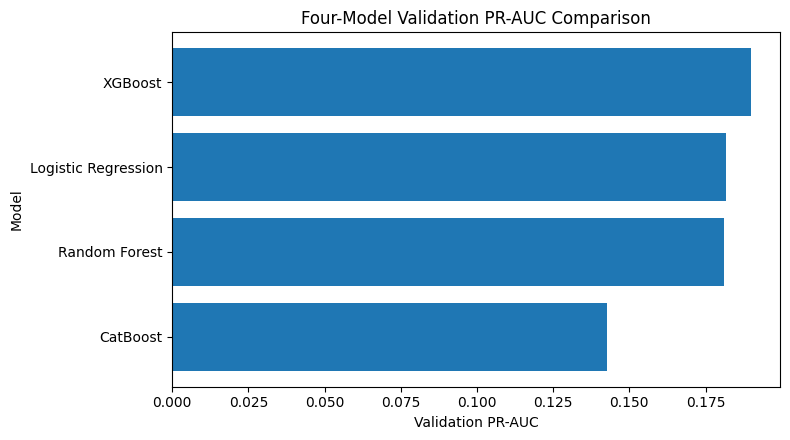

In [67]:
# 4.5.2 Plot validation PR-AUC

import matplotlib.pyplot as plt

plot_df = validation_model_comparison.sort_values("PR-AUC")

plt.figure(figsize=(8, 4.5))
plt.barh(plot_df["Model"], plot_df["PR-AUC"])
plt.xlabel("Validation PR-AUC")
plt.ylabel("Model")
plt.title("Four-Model Validation PR-AUC Comparison")
plt.tight_layout()
plt.show()


### Validation-selection rule

The model ranked first by validation PR-AUC is carried forward to threshold selection. This is a **validation-stage selection**, not a final test-set result.

Do not unlock the test set yet. First choose and document the operating threshold using validation predictions; then lock the selected model and threshold before the one-time final test evaluation.


## 4.6 XGBoost Validation-Only Decision-Threshold Tuning

The four-model comparison selected **XGBoost** using validation PR-AUC. The next step is to choose its classification threshold **without using the test set**.

Because the positive class is `<30` readmission and missing a genuinely high-risk patient can be important, **F2 is used as the primary threshold-selection criterion**. F2 gives recall more weight than precision. Precision, recall and F1 are still reported so the trade-off remains transparent.

The threshold selected here is locked before the final held-out test evaluation.


In [68]:
# 4.6.1 Evaluate XGBoost across validation thresholds ONLY

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

# best_xgb_valid_prob was created in Model 3 from X_valid_xgb.
# No test probabilities are created or accessed in this section.

threshold_grid = np.round(np.arange(0.10, 0.71, 0.02), 2)

threshold_rows = []

for threshold in threshold_grid:
    pred = (best_xgb_valid_prob >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_valid, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, pred, zero_division=0
        ),
        "F1": f1_score(
            y_valid, pred, zero_division=0
        ),
        "F2": fbeta_score(
            y_valid, pred, beta=2, zero_division=0
        ),
        "Predicted Positive Rate": pred.mean()
    })

xgb_threshold_results = pd.DataFrame(threshold_rows)

display(
    xgb_threshold_results.sort_values(
        "Threshold"
    ).reset_index(drop=True)
)


,Threshold,Precision,Recall,F1,F2,Predicted Positive Rate
0,0.10,0.110202,1.000000,0.198525,0.382430,1.000000
1,0.12,0.110202,1.000000,0.198525,0.382430,1.000000
2,0.14,0.110297,1.000000,0.198680,0.382660,0.999135
3,0.16,0.110466,1.000000,0.198955,0.383067,0.997604
4,0.18,0.110762,1.000000,0.199434,0.383778,0.994942
5,0.20,0.110992,0.998792,0.199783,0.384187,0.991682
6,0.22,0.111404,0.996981,0.200413,0.384956,0.986225
7,0.24,0.112178,0.994565,0.201616,0.386511,0.977041
8,0.26,0.113127,0.990338,0.203058,0.388239,0.964730
9,0.28,0.113809,0.979469,0.203923,0.388484,0.948426


In [69]:
# 4.6.2 Select the threshold with the highest validation F2

best_threshold_row = (
    xgb_threshold_results
    .sort_values(
        ["F2", "F1", "Precision"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

selected_xgb_threshold = float(
    best_threshold_row["Threshold"]
)

print("VALIDATION-SELECTED XGBOOST THRESHOLD")
print("--------------------------------------")
print(f"Threshold : {selected_xgb_threshold:.2f}")
print(f"Precision : {best_threshold_row['Precision']:.4f}")
print(f"Recall    : {best_threshold_row['Recall']:.4f}")
print(f"F1        : {best_threshold_row['F1']:.4f}")
print(f"F2        : {best_threshold_row['F2']:.4f}")
print(
    "Predicted positive rate:",
    f"{best_threshold_row['Predicted Positive Rate']:.4f}"
)

print("\nSelection rule: maximum validation F2.")
print("TEST SET STATUS: LOCKED")


VALIDATION-SELECTED XGBOOST THRESHOLD
--------------------------------------
Threshold : 0.42
Precision : 0.1374
Recall    : 0.7699
F1        : 0.2332
F2        : 0.4009
Predicted positive rate: 0.6174

Selection rule: maximum validation F2.
TEST SET STATUS: LOCKED


In [70]:
# 4.6.3 Show useful threshold comparisons around the selected operating point

comparison_thresholds = sorted(set([
    0.20, 0.25, 0.30, 0.35, 0.40,
    0.45, 0.50,
    selected_xgb_threshold
]))

threshold_comparison = (
    xgb_threshold_results[
        xgb_threshold_results["Threshold"].isin(
            comparison_thresholds
        )
    ]
    .sort_values("Threshold")
    .reset_index(drop=True)
)

display(threshold_comparison)


,Threshold,Precision,Recall,F1,F2,Predicted Positive Rate
0,0.20,0.110992,0.998792,0.199783,0.384187,0.991682
1,0.30,0.115742,0.971014,0.206830,0.391870,0.924536
2,0.40,0.131254,0.820652,0.226311,0.400224,0.689026
3,0.42,0.137437,0.769928,0.233239,0.400918,0.617355
4,0.50,0.161856,0.518116,0.246658,0.359748,0.352765


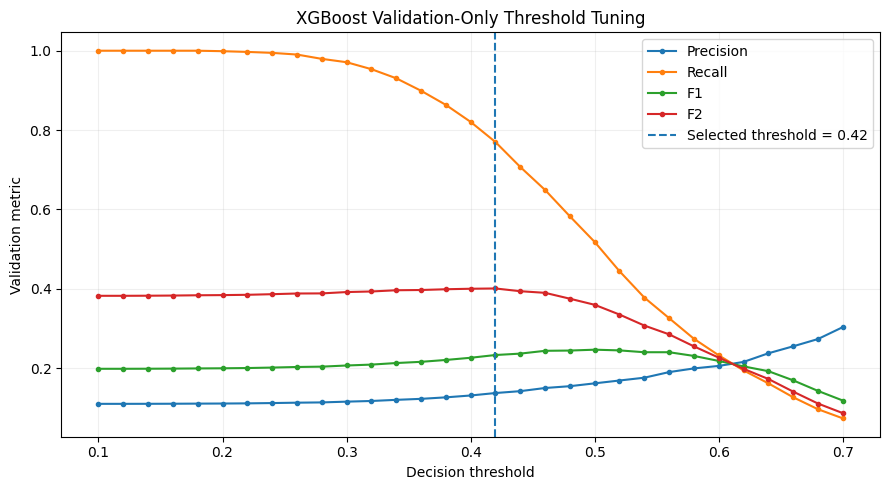

In [71]:
# 4.6.4 Plot validation precision, recall, F1 and F2 by threshold

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1", "F2"]:
    plt.plot(
        xgb_threshold_results["Threshold"],
        xgb_threshold_results[metric],
        marker="o",
        markersize=3,
        label=metric
    )

plt.axvline(
    selected_xgb_threshold,
    linestyle="--",
    label=f"Selected threshold = {selected_xgb_threshold:.2f}"
)

plt.xlabel("Decision threshold")
plt.ylabel("Validation metric")
plt.title("XGBoost Validation-Only Threshold Tuning")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [72]:
# 4.6.5 Validation confusion matrix at the locked threshold

xgb_valid_pred_locked = (
    best_xgb_valid_prob >= selected_xgb_threshold
).astype(int)

xgb_locked_validation_cm = confusion_matrix(
    y_valid,
    xgb_valid_pred_locked
)

print(
    f"Validation confusion matrix at threshold "
    f"{selected_xgb_threshold:.2f}:"
)
print(xgb_locked_validation_cm)


Validation confusion matrix at threshold 0.42:
[[5369 8002]
 [ 381 1275]]


### Threshold-selection decision

The recommended operating threshold is the threshold stored in `selected_xgb_threshold`, chosen by **maximum validation F2**.

This is preferable to automatically retaining 0.50 because the target is imbalanced and the project is intended to identify patients at risk of `<30` readmission. F2 deliberately places more emphasis on recall while still penalizing excessive false-positive predictions.

The final report should state the actual selected threshold and its validation precision, recall, F1 and F2 after this cell has executed. The choice is a predictive operating-point decision, not a clinical treatment rule.

**Test-set lock:** no test probability, prediction, confusion matrix, or test metric is calculated in this section. After this threshold is fixed, the selected XGBoost configuration and this threshold can be evaluated once on the held-out test set.


---
# PART 5 — SECONDARY MEDICATION/TREATMENT ANALYSIS

**Owner: Member 4 — Vishwajith U.K.S.B.**


## 18. Secondary Medication/Treatment Pattern Analysis — Complete

This analysis uses the **training split only** (`X_train_fe` + `y_train`) so the untouched test set remains reserved for the one-time final evaluation in Part 6. The purpose is to identify **associations**, not causal effects. Statistical significance is reported together with effect size and descriptive readmission rates.

Analyses cover `change`, `insulin`, `diabetesMed`, engineered medication count/adjustment features, and total medication burden (`num_medications`).


In [73]:
# 18.0 Secondary-analysis setup — TRAINING DATA ONLY
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr
from math import sqrt, log, exp

secondary_df = X_train_fe.copy()
secondary_df["readmit_30"] = np.asarray(y_train).astype(int)

print("Secondary-analysis encounters:", f"{len(secondary_df):,}")
print("Training positive rate:", f"{secondary_df['readmit_30'].mean():.4f}")
print("Test set used here: NO")

def rate_table(data, feature):
    out = (data.groupby(feature, dropna=False)["readmit_30"]
              .agg(count="size", positives="sum", readmit_30_rate="mean")
              .sort_values("count", ascending=False))
    out["readmit_30_rate_pct"] = 100 * out["readmit_30_rate"]
    return out

def cramers_v(data, feature, target="readmit_30"):
    tab = pd.crosstab(data[feature].fillna("Missing"), data[target])
    chi2, p, dof, expected = chi2_contingency(tab)
    n = tab.to_numpy().sum()
    denom = max(1, min(tab.shape[0] - 1, tab.shape[1] - 1))
    v = sqrt((chi2 / n) / denom) if n else np.nan
    return chi2, p, dof, v, tab

def binary_odds_ratio(data, feature, exposed_value, reference_value, target="readmit_30"):
    d = data[data[feature].isin([exposed_value, reference_value])].copy()
    t = pd.crosstab(d[feature], d[target]).reindex(index=[exposed_value, reference_value], columns=[0,1], fill_value=0)
    a=float(t.loc[exposed_value,1]); b=float(t.loc[exposed_value,0])
    c=float(t.loc[reference_value,1]); d0=float(t.loc[reference_value,0])
    # Haldane-Anscombe correction only if a zero cell occurs.
    if min(a,b,c,d0) == 0:
        a+=0.5; b+=0.5; c+=0.5; d0+=0.5
    or_value=(a*d0)/(b*c)
    se=sqrt(1/a+1/b+1/c+1/d0)
    lo=exp(log(or_value)-1.96*se); hi=exp(log(or_value)+1.96*se)
    return or_value, lo, hi

def plot_rate_table(tbl, title, xlabel):
    ax = tbl["readmit_30_rate_pct"].plot(kind="bar", figsize=(8,4))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("30-day readmission rate (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


Secondary-analysis encounters: 71,520
Training positive rate: 0.1122
Test set used here: NO


,count,positives,readmit_30_rate,readmit_30_rate_pct
change,,,,
No,38519,4109,0.106675,10.667463
Ch,33001,3912,0.118542,11.854186


Chi-square = 25.019; dof = 1; p = 5.6765e-07; Cramer's V = 0.0187
Odds ratio (Ch vs No) = 1.126 (95% CI 1.075–1.180)


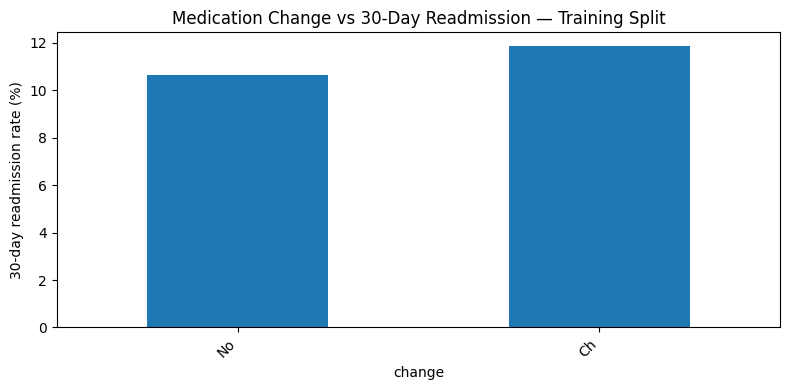

In [74]:
# 18.1 Medication change (`change`) vs 30-day readmission
change_table = rate_table(secondary_df, "change")
display(change_table)
chi2, p, dof, v, _ = cramers_v(secondary_df, "change")
print(f"Chi-square = {chi2:.3f}; dof = {dof}; p = {p:.6g}; Cramer's V = {v:.4f}")
if {"Ch", "No"}.issubset(set(secondary_df["change"].dropna().unique())):
    orv, lo, hi = binary_odds_ratio(secondary_df, "change", "Ch", "No")
    print(f"Odds ratio (Ch vs No) = {orv:.3f} (95% CI {lo:.3f}–{hi:.3f})")
plot_rate_table(change_table, "Medication Change vs 30-Day Readmission — Training Split", "change")


,count,positives,readmit_30_rate,readmit_30_rate_pct
insulin,,,,
No,33227,3310,0.099618,9.961778
Steady,21723,2444,0.112507,11.250748
Down,8573,1213,0.141491,14.149073
Up,7997,1054,0.131799,13.179942


Chi-square = 157.566; dof = 3; p = 6.144e-34; Cramer's V = 0.0469
Reference-free interpretation: Cramer's V summarizes the overall association across insulin categories.


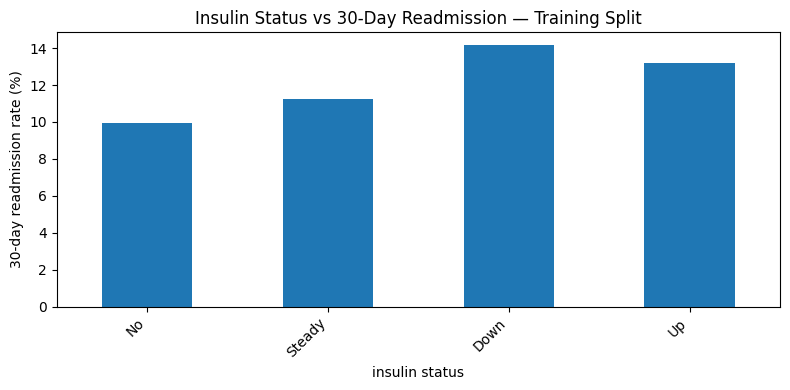

In [75]:
# 18.2 Insulin status vs 30-day readmission
insulin_table = rate_table(secondary_df, "insulin")
display(insulin_table)
chi2, p, dof, v, _ = cramers_v(secondary_df, "insulin")
print(f"Chi-square = {chi2:.3f}; dof = {dof}; p = {p:.6g}; Cramer's V = {v:.4f}")
print("Reference-free interpretation: Cramer's V summarizes the overall association across insulin categories.")
plot_rate_table(insulin_table, "Insulin Status vs 30-Day Readmission — Training Split", "insulin status")


,count,positives,readmit_30_rate,readmit_30_rate_pct
diabetesMed,,,,
Yes,55113,6459,0.117196,11.719558
No,16407,1562,0.095203,9.520327


Chi-square = 61.192; dof = 1; p = 5.17745e-15; Cramer's V = 0.0293
Odds ratio (Yes vs No) = 1.262 (95% CI 1.190–1.337)


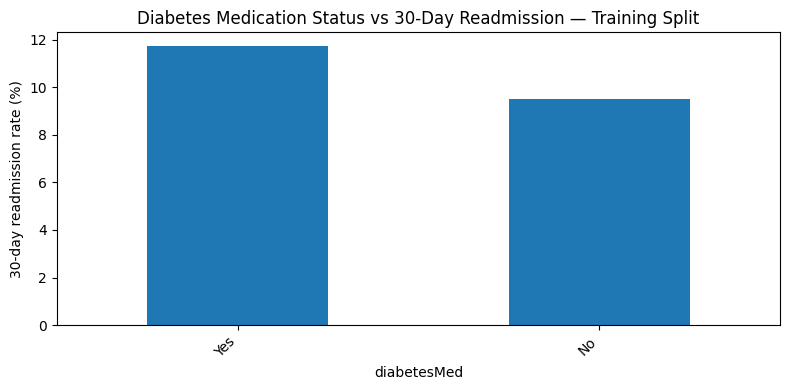

In [76]:
# 18.3 Diabetes medication status (`diabetesMed`)
diabetesmed_table = rate_table(secondary_df, "diabetesMed")
display(diabetesmed_table)
chi2, p, dof, v, _ = cramers_v(secondary_df, "diabetesMed")
print(f"Chi-square = {chi2:.3f}; dof = {dof}; p = {p:.6g}; Cramer's V = {v:.4f}")
if {"Yes", "No"}.issubset(set(secondary_df["diabetesMed"].dropna().unique())):
    orv, lo, hi = binary_odds_ratio(secondary_df, "diabetesMed", "Yes", "No")
    print(f"Odds ratio (Yes vs No) = {orv:.3f} (95% CI {lo:.3f}–{hi:.3f})")
plot_rate_table(diabetesmed_table, "Diabetes Medication Status vs 30-Day Readmission — Training Split", "diabetesMed")



diabetes_medication_count


,count,positives,readmit_30_rate,readmit_30_rate_pct
diabetes_medication_count,,,,
1,33461,4172,0.124682,12.468247
0,16407,1562,0.095203,9.520327
2,15239,1630,0.106962,10.696240
3,5442,567,0.104190,10.418964
4,931,90,0.096670,9.667025
5,37,0,0.000000,0.000000
6,3,0,0.000000,0.000000


Spearman rho = 0.0064; p = 0.0873335


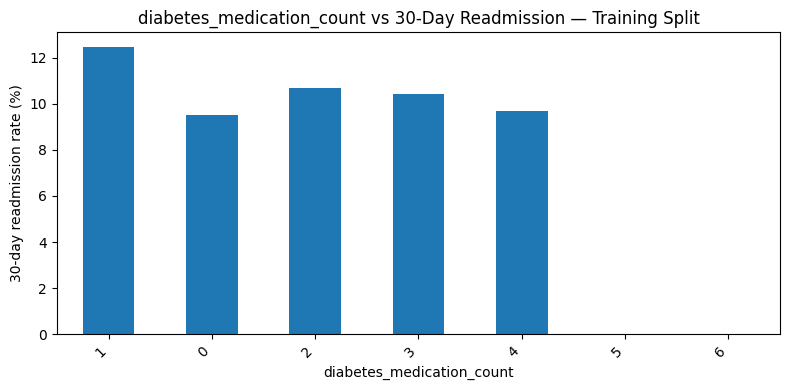


medication_adjustment_count


,count,positives,readmit_30_rate,readmit_30_rate_pct
medication_adjustment_count,,,,
0,52064,5452,0.104717,10.471727
1,18509,2452,0.132476,13.247609
2,858,104,0.121212,12.121212
3,85,13,0.152941,15.294118
4,4,0,0.000000,0.000000


Spearman rho = 0.0382; p = 1.49747e-24


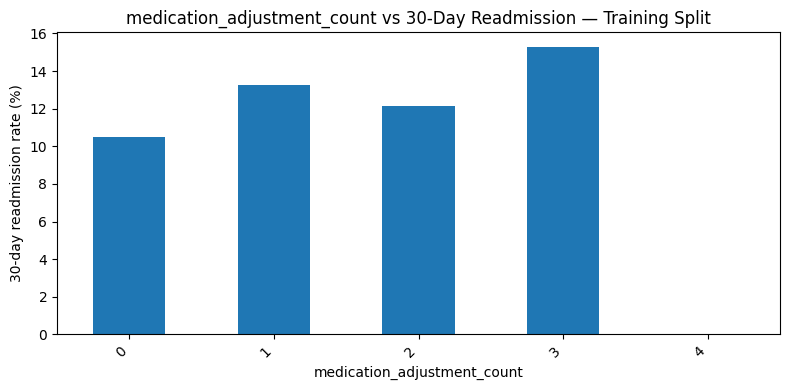


Any medication adjustment


,count,positives,readmit_30_rate,readmit_30_rate_pct
any_medication_adjustment,,,,
0,52064,5452,0.104717,10.471727
1,19456,2569,0.132042,13.204153


Chi-square = 105.925; p = 7.65929e-25; Cramer's V = 0.0385


In [77]:
# 18.4 Diabetes-medication diversity and adjustment count
count_results = {}
for feature in ["diabetes_medication_count", "medication_adjustment_count"]:
    if feature not in secondary_df.columns:
        print(f"{feature}: not available")
        continue
    tmp = secondary_df[[feature, "readmit_30"]].copy()
    tmp[feature] = pd.to_numeric(tmp[feature], errors="coerce")
    tbl = rate_table(tmp.dropna(), feature)
    count_results[feature] = tbl
    print(f"\n{feature}")
    display(tbl)
    rho, p = spearmanr(tmp[feature], tmp["readmit_30"], nan_policy="omit")
    print(f"Spearman rho = {rho:.4f}; p = {p:.6g}")
    plot_rate_table(tbl, f"{feature} vs 30-Day Readmission — Training Split", feature)

if "any_medication_adjustment" in secondary_df.columns:
    any_adjust_table = rate_table(secondary_df, "any_medication_adjustment")
    print("\nAny medication adjustment")
    display(any_adjust_table)
    chi2, p, dof, v, _ = cramers_v(secondary_df, "any_medication_adjustment")
    print(f"Chi-square = {chi2:.3f}; p = {p:.6g}; Cramer's V = {v:.4f}")


,count,mean,median,std
readmit_30,,,,
0,63499,15.906928,15.0,8.130140
1,8021,16.839172,16.0,8.103111


Mann–Whitney U p = 2.42848e-30; rank-biserial effect = 0.0782
Spearman rho = 0.0428; p = 2.28897e-30


/tmp/ipykernel_1891/171196611.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = (data.groupby(feature, dropna=False)["readmit_30"]


,count,positives,readmit_30_rate,readmit_30_rate_pct
medication_burden_group,,,,
11–20,36608,4209,0.114975,11.497487
0–10,18200,1674,0.091978,9.197802
21–30,13034,1687,0.129431,12.943072
31+,3678,451,0.122621,12.262099


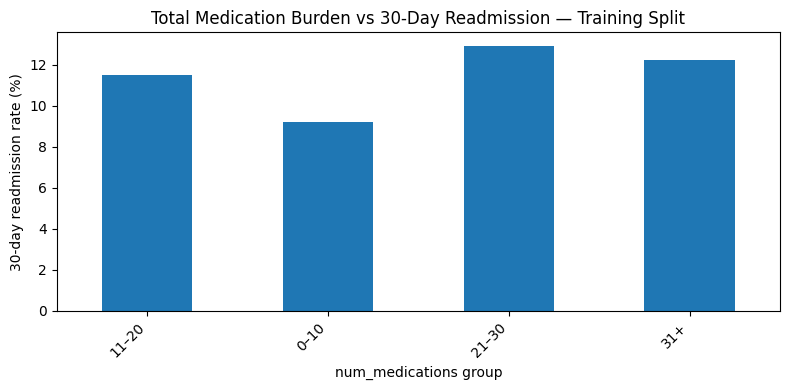

In [78]:
# 18.5 Total medication burden (`num_medications`)
medburden = secondary_df[["num_medications", "readmit_30"]].copy()
medburden["num_medications"] = pd.to_numeric(medburden["num_medications"], errors="coerce")
medburden = medburden.dropna()

summary_medburden = medburden.groupby("readmit_30")["num_medications"].agg(["count", "mean", "median", "std"])
display(summary_medburden)

pos = medburden.loc[medburden["readmit_30"] == 1, "num_medications"]
neg = medburden.loc[medburden["readmit_30"] == 0, "num_medications"]
u_stat, u_p = mannwhitneyu(pos, neg, alternative="two-sided")
rank_biserial = (2 * u_stat) / (len(pos) * len(neg)) - 1
rho, rho_p = spearmanr(medburden["num_medications"], medburden["readmit_30"])
print(f"Mann–Whitney U p = {u_p:.6g}; rank-biserial effect = {rank_biserial:.4f}")
print(f"Spearman rho = {rho:.4f}; p = {rho_p:.6g}")

# Descriptive bins chosen for readability; inferential test above uses the original numeric values.
medburden["medication_burden_group"] = pd.cut(
    medburden["num_medications"],
    bins=[-np.inf, 10, 20, 30, np.inf],
    labels=["0–10", "11–20", "21–30", "31+"]
)
medburden_table = rate_table(medburden, "medication_burden_group")
display(medburden_table)
plot_rate_table(medburden_table, "Total Medication Burden vs 30-Day Readmission — Training Split", "num_medications group")


### 18.6 Interpretation rule

For the secondary objective, compare **readmission rates**, **effect sizes**, and uncertainty together. A small p-value does not by itself imply a practically important relationship, especially with a large dataset. Medication variables may reflect disease severity, comorbidity, treatment intensity, or other confounding factors. Therefore, all findings below must be described as **associations with 30-day readmission**, not medication effects or causal effects.


## 19. Cross-Reference Secondary Findings with Model Feature Importance

The following cell cross-references medication variables with the already-fitted Random Forest, XGBoost and CatBoost models. For one-hot encoded tree models, importances for encoded levels belonging to the same source variable are summed. This is descriptive model interpretation and is **not causal evidence**.


In [79]:
# 19.1 Aggregate medication-related feature importance across fitted tree models
medication_features_for_review = [
    "change", "insulin", "diabetesMed", "num_medications",
    "diabetes_medication_count", "medication_adjustment_count",
    "any_medication_adjustment"
]

def encoded_importance_for_source(importance_df, source_feature):
    # sklearn names are typically numeric__feature or categorical__feature_level.
    f = importance_df["feature"].astype(str)
    mask = (f == source_feature) | f.str.contains(rf"(^|__){source_feature}($|_)", regex=True)
    return float(importance_df.loc[mask, "importance"].sum())

# XGBoost importances already exist as xgb_importance_df.
xgb_med_importance = {f: encoded_importance_for_source(xgb_importance_df, f) for f in medication_features_for_review}

# Random Forest: extract transformed feature names and fitted RF importances.
rf_pre = best_random_forest_model.named_steps["preprocess"]
rf_est = best_random_forest_model.named_steps["model"]
rf_importance_df = pd.DataFrame({
    "feature": rf_pre.get_feature_names_out(),
    "importance": rf_est.feature_importances_
})
rf_med_importance = {f: encoded_importance_for_source(rf_importance_df, f) for f in medication_features_for_review}

# CatBoost uses original/engineered column names directly.
cat_med_importance = (catboost_importance_df.set_index("feature")["importance"].to_dict())

importance_crossref = pd.DataFrame({
    "Medication feature": medication_features_for_review,
    "RF importance (aggregated)": [rf_med_importance.get(f, 0.0) for f in medication_features_for_review],
    "XGB importance (aggregated)": [xgb_med_importance.get(f, 0.0) for f in medication_features_for_review],
    "CatBoost importance": [float(cat_med_importance.get(f, 0.0)) for f in medication_features_for_review]
})
importance_crossref["Present in all 3 importance views"] = (
    (importance_crossref["RF importance (aggregated)"] > 0) &
    (importance_crossref["XGB importance (aggregated)"] > 0) &
    (importance_crossref["CatBoost importance"] > 0)
)
display(importance_crossref.sort_values("XGB importance (aggregated)", ascending=False))


/tmp/ipykernel_1891/2249191286.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = (f == source_feature) | f.str.contains(rf"(^|__){source_feature}($|_)", regex=True)
/tmp/ipykernel_1891/2249191286.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = (f == source_feature) | f.str.contains(rf"(^|__){source_feature}($|_)", regex=True)
/tmp/ipykernel_1891/2249191286.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = (f == source_feature) | f.str.contains(rf"(^|__){source_feature}($|_)", regex=True)
/tmp/ipykernel_1891/2249191286.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = (f == source_feature) | f.st

,Medication feature,RF importance (aggregated),XGB importance (aggregated),CatBoost importance,Present in all 3 importance views
2,diabetesMed,0.009710,0.010702,0.0,False
1,insulin,0.017928,0.008498,0.0,False
4,diabetes_medication_count,0.010569,0.003494,0.0,False
6,any_medication_adjustment,0.005029,0.003438,0.0,False
3,num_medications,0.031768,0.002358,0.0,False
5,medication_adjustment_count,0.006334,0.002299,0.0,False
0,change,0.006865,0.001202,0.0,False


In [80]:
# 19.2 Compact statistical-association summary for categorical medication variables
association_rows = []
for feature in ["change", "insulin", "diabetesMed", "any_medication_adjustment"]:
    if feature in secondary_df.columns:
        chi2, p, dof, v, _ = cramers_v(secondary_df, feature)
        association_rows.append({
            "feature": feature, "test": "Chi-square", "p_value": p, "effect_size": v, "effect": "Cramer's V"
        })
for feature in ["diabetes_medication_count", "medication_adjustment_count", "num_medications"]:
    if feature in secondary_df.columns:
        x = pd.to_numeric(secondary_df[feature], errors="coerce")
        rho, p = spearmanr(x, secondary_df["readmit_30"], nan_policy="omit")
        association_rows.append({
            "feature": feature, "test": "Spearman", "p_value": p, "effect_size": rho, "effect": "rho"
        })
association_summary = pd.DataFrame(association_rows)
display(association_summary)


,feature,test,p_value,effect_size,effect
0,change,Chi-square,5.676504e-07,0.018703,Cramer's V
1,insulin,Chi-square,6.143995e-34,0.046937,Cramer's V
2,diabetesMed,Chi-square,5.177450e-15,0.029250,Cramer's V
3,any_medication_adjustment,Chi-square,7.659294e-25,0.038484,Cramer's V
4,diabetes_medication_count,Spearman,8.733351e-02,0.006393,rho
5,medication_adjustment_count,Spearman,1.497467e-24,0.038229,rho
6,num_medications,Spearman,2.288968e-30,0.042804,rho


### Member 4 Summary & Key Findings

After running Part 5 top-to-bottom, use the displayed tables to write the final summary. Report: (1) which medication/treatment categories have higher or lower observed `<30` readmission rates, (2) whether effect sizes are weak/moderate/strong rather than relying only on p-values, (3) whether the same variables receive non-zero predictive importance across RF/XGBoost/CatBoost, and (4) the limitation that these are **observational associations, not causal treatment effects**.

**Test-set status after Part 5: still untouched.** The selected XGBoost model and `selected_xgb_threshold` are not modified anywhere in this section.


---
# PART 6 — FOUR-MODEL COMPARISON, THRESHOLD SELECTION & FINAL EVALUATION

**Owner: Group**

This part records the already-completed validation-based model selection, validation-only threshold selection, and the one-time held-out test evaluation. The test set must not be used for any further tuning.


## 20. Four-Model Validation Comparison

All four candidate models were compared on the same validation split. The pre-established selection criterion was **validation PR-AUC**, which is appropriate for the imbalanced `<30` readmission target.

| Rank | Model | PR-AUC | ROC-AUC | Precision | Recall | F1 | F2 | Balanced Accuracy |
|---:|---|---:|---:|---:|---:|---:|---:|---:|
| 1 | XGBoost | 0.189940 | 0.633847 | 0.161856 | 0.518116 | 0.246658 | 0.359748 | 0.592915 |
| 2 | Logistic Regression | 0.181569 | 0.629251 | 0.160698 | 0.528382 | 0.246444 | 0.362499 | 0.593299 |
| 3 | Random Forest | 0.181198 | 0.637163 | 0.179949 | 0.380435 | 0.244328 | 0.311111 | 0.582858 |
| 4 | CatBoost | 0.142732 | 0.588585 | 0.141396 | 0.567633 | 0.226397 | 0.354129 | 0.570369 |

**Validation decision:** XGBoost was selected because it achieved the highest validation PR-AUC (0.1899). The test set was not used for this decision.


## 21. Validation-Only Operating Threshold Selection

After XGBoost was selected, its decision threshold was tuned using **validation predictions only**. The threshold search maximized **F2**, giving greater weight to recall because the intended use is readmission-risk screening.

The locked threshold was **0.42**.

Validation performance at 0.42:

| Metric | Validation result |
|---|---:|
| Precision | 0.1374 |
| Recall | 0.7699 |
| F1 | 0.2332 |
| F2 | 0.4009 |
| Predicted-positive rate | 61.74% |

Once selected, the model and threshold were frozen before the test set was evaluated.


## 22. One-Time Final Test Evaluation — Locked XGBoost

The following cell performs the final held-out evaluation using the already-selected **XGBoost model** and **0.42 validation-selected threshold**. It must not be used to retune the model, features, hyperparameters, or threshold.


In [81]:
# 22.2 FINAL ONE-TIME TEST EVALUATION
# Locked model: best_xgboost_model
# Locked threshold: selected_xgb_threshold (chosen on validation data only)
# IMPORTANT: Do not retune anything based on the results below.

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

# Transform the untouched engineered test matrix using the tree preprocessor
# that was already fitted on TRAINING data in Section 4.3.3.
X_test_xgb = tree_preprocessor.transform(X_test_model)

# Generate final test probabilities with the validation-selected XGBoost model.
best_xgb_test_prob = best_xgboost_model.predict_proba(X_test_xgb)[:, 1]

# Apply the operating threshold that was locked using validation F2.
best_xgb_test_pred = (
    best_xgb_test_prob >= selected_xgb_threshold
).astype(int)

# Threshold-independent metrics.
final_test_pr_auc = average_precision_score(y_test, best_xgb_test_prob)
final_test_roc_auc = roc_auc_score(y_test, best_xgb_test_prob)

# Threshold-dependent metrics at the locked threshold.
final_test_precision = precision_score(
    y_test, best_xgb_test_pred, zero_division=0
)
final_test_recall = recall_score(
    y_test, best_xgb_test_pred, zero_division=0
)
final_test_f1 = f1_score(
    y_test, best_xgb_test_pred, zero_division=0
)
final_test_f2 = fbeta_score(
    y_test, best_xgb_test_pred, beta=2, zero_division=0
)
final_test_balanced_accuracy = balanced_accuracy_score(
    y_test, best_xgb_test_pred
)
final_test_cm = confusion_matrix(y_test, best_xgb_test_pred)

# Store the final result in a compact table for later reporting.
final_test_metrics = pd.DataFrame([{
    "Model": "XGBoost",
    "Threshold": selected_xgb_threshold,
    "ROC-AUC": final_test_roc_auc,
    "PR-AUC": final_test_pr_auc,
    "Precision": final_test_precision,
    "Recall": final_test_recall,
    "F1": final_test_f1,
    "F2": final_test_f2,
    "Balanced Accuracy": final_test_balanced_accuracy,
    "Actual Positive Rate": y_test.mean(),
    "Predicted Positive Rate": best_xgb_test_pred.mean()
}])

print("=" * 64)
print("FINAL ONE-TIME TEST EVALUATION — LOCKED XGBOOST")
print("=" * 64)
print(f"Locked threshold        : {selected_xgb_threshold:.2f}")
print(f"Test encounters         : {len(y_test):,}")
print(f"Actual positive rate    : {y_test.mean():.4f}")
print(f"Predicted positive rate : {best_xgb_test_pred.mean():.4f}")
print()
display(final_test_metrics)

print("CONFUSION MATRIX [[TN, FP], [FN, TP]]")
print(final_test_cm)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    best_xgb_test_pred,
    target_names=["Not <30", "<30"],
    zero_division=0
))

print("=" * 64)
print("TEST SET HAS NOW BEEN USED FOR FINAL EVALUATION.")
print("Do not retune the model or threshold using these test results.")
print("=" * 64)


FINAL ONE-TIME TEST EVALUATION — LOCKED XGBOOST
Locked threshold        : 0.42
Test encounters         : 15,219
Actual positive rate    : 0.1104
Predicted positive rate : 0.6130



,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1,F2,Balanced Accuracy,Actual Positive Rate,Predicted Positive Rate
0,XGBoost,0.42,0.655522,0.209902,0.140958,0.782738,0.238895,0.409683,0.595409,0.110388,0.612984


CONFUSION MATRIX [[TN, FP], [FN, TP]]
[[5525 8014]
 [ 365 1315]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Not <30       0.94      0.41      0.57     13539
         <30       0.14      0.78      0.24      1680

    accuracy                           0.45     15219
   macro avg       0.54      0.60      0.40     15219
weighted avg       0.85      0.45      0.53     15219

TEST SET HAS NOW BEEN USED FOR FINAL EVALUATION.
Do not retune the model or threshold using these test results.


### 22.3 Frozen Final Test Result

The one-time test run produced the following final results:

| Metric | Final test result |
|---|---:|
| ROC-AUC | 0.6555 |
| PR-AUC | 0.2099 |
| Precision | 0.1410 |
| Recall | 0.7827 |
| F1 | 0.2389 |
| F2 | 0.4097 |
| Balanced Accuracy | 0.5954 |
| Actual `<30` rate | 11.04% |
| Predicted-positive rate | 61.30% |

Final confusion matrix: **TN = 5,525, FP = 8,014, FN = 365, TP = 1,315**.

The model detected approximately 78.3% of actual `<30` readmissions, but the low precision and 8,014 false positives show that it should be interpreted as a high-recall screening tool rather than a definitive readmission decision system. Validation and test threshold metrics were similar, supporting reasonable held-out consistency without implying external generalisability.


---
# PART 7 — INTEGRATED INTERPRETATION & HOSPITAL RECOMMENDATION

**Owner: Group**

## 23. Integrated Interpretation

The final XGBoost model was selected using validation PR-AUC and evaluated once on the untouched patient-group test set after the decision threshold had been fixed at **0.42** using validation F2. On the final test set, ROC-AUC was **0.6555** and PR-AUC was **0.2099**. At the locked threshold, precision was **0.1410**, recall **0.7827**, F1 **0.2389**, F2 **0.4097**, and balanced accuracy **0.5954**.

Of 1,680 actual `<30` readmissions, 1,315 were detected and 365 were missed. However, 8,014 encounters were false positives. Approximately 61.3% of test encounters were flagged positive even though the actual positive rate was approximately 11.0%. The model therefore prioritizes sensitivity over diagnostic certainty.

The secondary medication/treatment analysis adds context rather than a causal explanation. Insulin status, medication adjustment, diabetes-medication status, medication change, and overall medication burden showed statistically detectable but generally small associations with readmission. These variables should be treated as supporting indicators within a broader risk profile, not as independent causes of readmission.


## 24. Hospital Recommendation

The final model is most defensibly used as a **first-stage, high-recall decision-support screen**. A positive model flag should trigger additional review rather than automatically determine treatment, discharge, medication changes, or allocation of expensive interventions.

A practical workflow is:

**Hospital encounter → XGBoost risk score → locked 0.42 screening threshold → risk flag → secondary clinical review → human decision**

The secondary review can consider prior healthcare utilisation, diagnoses/comorbidities, medication burden, recent medication adjustments, insulin status, and other clinically relevant information available to the care team. Lower-cost follow-up or review may be suitable for the broad flagged population, whereas resource-intensive interventions should require additional clinical assessment.

Because precision is approximately 14.1%, the false-positive burden is operationally important. The model should complement professional judgement rather than replace it.


---
# PART 8 — LIMITATIONS, RISKS & RESPONSIBLE AI

**Owner: Group**

## 25. Limitations and Risks

**Historical data.** The dataset covers 1999–2008. Clinical practice, diabetes treatment, coding, discharge processes, and hospital operations may have changed, so the results should not be assumed to represent current practice without external validation.

**Class imbalance.** Only about 11% of encounters are `<30` positives. Accuracy alone is therefore misleading; PR-AUC, recall, F2, balanced accuracy, and the confusion matrix were emphasized.

**False positives.** At threshold 0.42 the model generated 8,014 false positives and flagged about 61.3% of test encounters. Using every positive flag to trigger an expensive intervention could create unnecessary workload, resource use, and alert fatigue.

**False negatives.** The model missed 365 actual `<30` readmissions. A negative prediction must not be interpreted as a guarantee that a patient will not be readmitted.

**Generalisability.** The patient-aware held-out test set estimates performance within this dataset, not across every hospital, country, time period, or future patient population. External and prospective validation would be required before deployment.

**Medication-analysis limits.** Medication/treatment findings are observational associations with generally small effect sizes. Treatment intensity may reflect underlying disease severity or clinical complexity. The analysis does not establish that a medication or treatment change causes readmission.

**Calibration.** The project did not establish that predicted probabilities are perfectly calibrated. The value 0.42 is an operating threshold selected to maximize validation F2; it is not a clinical probability boundary and does not mean every flagged patient has a 42% true readmission probability.

**Missing data.** Several variables contain substantial missingness. `weight` was excluded because of extreme missingness, while other missing categorical values were explicitly represented. Imputation/encoding cannot recreate information that was never recorded.

**Subgroup fairness.** Overall metrics do not prove equal performance across demographic or clinical subgroups. False-positive rates, false-negative rates, recall, precision, and calibration should be checked across sufficiently represented groups before real-world use.


## 26. Responsible AI and Human Oversight

The model should be treated as a **research/decision-support prototype**, not an autonomous clinical decision system. It must not independently determine discharge, medication changes, treatment eligibility, or allocation of critical resources.

Healthcare professionals should retain responsibility for final decisions and should be able to consider information unavailable to the model. Model outputs should be presented with context about high recall, low precision, and uncertainty.

Before real-world deployment, further work should include recent/local external validation, calibration assessment, subgroup/fairness evaluation, prospective clinical evaluation, operational cost analysis for false positives and false negatives, privacy/security governance, monitoring for data/performance drift, clinician override mechanisms, and periodic reassessment.


---
# PART 9 — REPRODUCIBILITY, DOCUMENTATION & AI-USE TRANSPARENCY

**Owner: Group**

## 27. Reproducibility Record

The notebook is designed to run sequentially using `diabetic_data.csv` and `IDS_mapping.csv` in the same working directory. Relative paths are used to avoid machine-specific file locations.

A patient-aware **70/15/15 train-validation-test split** was created using `patient_nbr` as the grouping variable and random state **42**. The split contained 71,520 training encounters, 15,027 validation encounters, and 15,219 test encounters, with zero patient overlap between partitions.

Target/leakage-related fields and unsuitable predictors were excluded before modelling. Learned preprocessing was fitted using training data only. Deterministic feature engineering was applied consistently to train, validation, and test partitions.

Four candidate models were developed: Logistic Regression, Random Forest, XGBoost, and CatBoost. XGBoost was selected by validation PR-AUC; threshold 0.42 was selected using validation F2; and the test set was evaluated once after both decisions were frozen.

The final test results are treated as the final performance estimate and must not be used for further tuning.


In [82]:
# 27.1 Package/version snapshot

import sklearn
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

import xgboost
import catboost
print("xgboost:", xgboost.__version__)
print("catboost:", catboost.__version__)


numpy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1
xgboost: 3.4.1
catboost: 1.2.10


## 28. AI-Use Transparency

Generative AI tools were used as development-support resources during this project. Assistance included explanation of machine-learning concepts and errors, code-structure review, debugging suggestions, interpretation support for statistical/model outputs, and improvement of documentation and written explanations.

AI-generated suggestions were not treated as experimental evidence by themselves. Numerical results were produced by executing the notebook on the supplied dataset. Model selection, threshold selection, and final conclusions were based on those computed results. The group remains responsible for understanding, verifying, and explaining the submitted workflow, code, outputs, and conclusions.


### 28.1 Final Reproducibility Checklist

- Input files use relative paths: `diabetic_data.csv` and `IDS_mapping.csv`.
- Random state 42 is retained where applicable.
- Patient overlap across train/validation/test remains zero.
- Learned preprocessing is fitted on training data only.
- XGBoost remains the frozen final model.
- The operating threshold remains 0.42.
- No tuning occurs after the final test evaluation.
- PART 5 medication-analysis outputs are retained.
- Package versions are recorded.
- Notebook outputs should match the final report.
- AI use is declared transparently.


---
# PART 10 — FINAL CONCLUSION

**Owner: Group**

## 29. Final Conclusion

This project investigated **30-day hospital readmission risk among diabetic inpatient encounters**, using readmission-risk prediction as the primary lens and medication/treatment pattern analysis as the supporting secondary lens.

Four classification models were compared, and **XGBoost** was selected using the predefined validation PR-AUC criterion. Its operating threshold was then fixed at **0.42** by maximizing validation F2. After both decisions were locked, the model was evaluated once on the held-out patient-group test set.

The final model achieved **ROC-AUC 0.6555, PR-AUC 0.2099, precision 0.1410, recall 0.7827, F1 0.2389, F2 0.4097, and balanced accuracy 0.5954**. It correctly detected 1,315 of 1,680 actual `<30` readmissions, but generated 8,014 false positives. The model therefore provides useful but limited high-recall screening information rather than definitive individual predictions.

The secondary analysis found statistically detectable but generally small associations between readmission and several medication/treatment characteristics, including insulin status, medication adjustment, diabetes-medication status, medication change, and overall medication burden. These findings provide contextual information but do not establish causal treatment effects.

For hospital use, the most defensible interpretation is a **first-stage risk-screening and prioritization tool followed by clinical review and human decision-making**. The false-positive burden, historical data, missing information, uncertain calibration, potential subgroup differences, and limited external generalisability prevent the model from being considered an autonomous or deployment-ready clinical system.

Overall, the project demonstrates a complete evidence-based machine-learning workflow spanning data understanding, leakage prevention, patient-aware splitting, preprocessing, feature engineering, four-model comparison, validation-based model and threshold selection, secondary analysis, held-out evaluation, practical recommendation, and responsible-AI assessment. External validation on recent and representative hospital data would be necessary before real-world clinical use.


---
# PART 11 — NEW ENCOUNTER PREDICTION DEMO

**Owner: Group**

## 30. New-Encounter Inference with the Frozen XGBoost Model

This section demonstrates the project's promised primary output for a **new hospital encounter**: a model risk score plus a clear risk flag.

It deliberately reuses the already-fitted objects from the completed workflow:

- `engineer_features(...)` — the existing deterministic feature-engineering function;
- `tree_preprocessor` — already fitted on the **training data only**;
- `best_xgboost_model` — the frozen validation-selected XGBoost estimator; and
- `selected_xgb_threshold` — the locked **0.42** validation-selected F2 threshold.

**Important:** this section performs inference only. It does **not** fit, retrain, retune, recalibrate, or modify the model or threshold. The displayed model probability is reported as a **risk score**, because dedicated probability calibration was not established in this project. A high-risk flag means the encounter is flagged as having elevated risk of readmission within 30 days after discharge and may be considered for additional clinical review. It does not mean that readmission will definitely occur.


In [83]:
# 30.1 Reusable prediction function for one or more NEW encounters

LOCKED_XGB_THRESHOLD = 0.42

# Protect the frozen operating point documented in Parts 6-10.
assert abs(float(selected_xgb_threshold) - LOCKED_XGB_THRESHOLD) < 1e-12, \
    "The selected threshold no longer matches the locked project threshold (0.42)."

# These are the raw predictor columns expected BEFORE feature engineering.
RAW_PREDICTOR_COLUMNS = [
    c for c in df.columns
    if c not in DROP_FROM_PREDICTORS
]

# Numeric source fields that must be numeric for feature engineering/model input.
NEW_INPUT_NUMERIC_COLUMNS = [
    c for c in NUMERIC_SOURCE_COLUMNS
    if c in RAW_PREDICTOR_COLUMNS
]


def predict_new_encounter(encounter_data):
    """Generate frozen-XGBoost risk output for new encounter data."""
    if isinstance(encounter_data, dict):
        new_raw = pd.DataFrame([encounter_data])
    elif isinstance(encounter_data, pd.DataFrame):
        new_raw = encounter_data.copy()
    else:
        raise TypeError("encounter_data must be a dict or pandas DataFrame.")

    missing_columns = [
        c for c in RAW_PREDICTOR_COLUMNS
        if c not in new_raw.columns
    ]
    extra_columns = [
        c for c in new_raw.columns
        if c not in RAW_PREDICTOR_COLUMNS
    ]

    if missing_columns:
        raise ValueError(
            "Missing required raw predictor columns: "
            + ", ".join(missing_columns)
        )

    if extra_columns:
        print("Ignoring extra columns:", extra_columns)

    # Match the raw predictor schema/order used during development.
    new_raw = new_raw[RAW_PREDICTOR_COLUMNS].copy()

    # Apply the same dataset-specific missing marker rule.
    new_raw = new_raw.replace("?", np.nan)

    # Apply the same numeric normalization used near the start of the notebook.
    for col in NEW_INPUT_NUMERIC_COLUMNS:
        new_raw[col] = pd.to_numeric(new_raw[col], errors="coerce")

    # Reuse the EXISTING deterministic feature engineering.
    new_engineered = engineer_features(new_raw)

    # Enforce exactly the finalized model feature schema.
    new_engineered = new_engineered.reindex(columns=X_train_model.columns)

    # Reuse the EXISTING preprocessor already fitted on TRAINING data only.
    new_xgb = tree_preprocessor.transform(new_engineered)

    # Reuse the FROZEN validation-selected XGBoost model.
    risk_scores = best_xgboost_model.predict_proba(new_xgb)[:, 1]
    high_risk_flag = risk_scores >= LOCKED_XGB_THRESHOLD

    result = pd.DataFrame({
        "Risk Score": risk_scores,
        "Locked Threshold": LOCKED_XGB_THRESHOLD,
        "Risk Classification": np.where(
            high_risk_flag,
            "HIGH-RISK FLAG",
            "LOWER-RISK FLAG"
        ),
        "Interpretation": np.where(
            high_risk_flag,
            "This encounter is flagged as having elevated risk of readmission within 30 days after discharge.",
            "This encounter is not flagged as elevated risk of readmission within 30 days after discharge at the locked 0.42 threshold."
        ),
        "Recommended Action": np.where(
            high_risk_flag,
            "Consider additional clinical review and appropriate follow-up planning.",
            "Continue usual clinical assessment and follow-up as appropriate. A lower-risk flag does not guarantee that readmission will not occur."
        )
    })

    return result


print("New-encounter prediction function ready.")
print("Raw predictor fields required:", len(RAW_PREDICTOR_COLUMNS))
print("Frozen model: best_xgboost_model")
print(f"Locked threshold: {LOCKED_XGB_THRESHOLD:.2f}")


New-encounter prediction function ready.
Raw predictor fields required: 43
Frozen model: best_xgboost_model
Locked threshold: 0.42


## 31. Example New Encounter

The dictionary below is an **illustrative input example** showing the raw fields expected by the trained workflow. Edit these values to demonstrate another encounter. Do not add target fields (`readmitted`, `readmit_30`) or excluded identifiers (`encounter_id`, `patient_nbr`).

Medication fields use the source dataset categories such as `No`, `Steady`, `Up`, and `Down`. Unknown categories can be handled by the fitted one-hot encoder, but real deployment would still require input validation and clinical data-governance checks.


In [84]:
# 31.1 EDIT THIS DICTIONARY to demonstrate a different new encounter

new_encounter = {
    "race": "Caucasian",
    "gender": "Female",
    "age": "[70-80)",
    "admission_type_id": 1,
    "admission_source_id": 7,
    "time_in_hospital": 5,
    "payer_code": "MC",
    "medical_specialty": "InternalMedicine",
    "num_lab_procedures": 55,
    "num_procedures": 1,
    "num_medications": 18,
    "number_outpatient": 1,
    "number_emergency": 1,
    "number_inpatient": 2,
    "diag_1": "250.6",
    "diag_2": "401",
    "diag_3": "428",
    "number_diagnoses": 8,
    "max_glu_serum": "None",
    "A1Cresult": ">8",
    "metformin": "Steady",
    "repaglinide": "No",
    "nateglinide": "No",
    "chlorpropamide": "No",
    "glimepiride": "No",
    "acetohexamide": "No",
    "glipizide": "No",
    "glyburide": "No",
    "tolbutamide": "No",
    "pioglitazone": "No",
    "rosiglitazone": "No",
    "acarbose": "No",
    "miglitol": "No",
    "troglitazone": "No",
    "tolazamide": "No",
    "insulin": "Up",
    "glyburide-metformin": "No",
    "glipizide-metformin": "No",
    "glimepiride-pioglitazone": "No",
    "metformin-rosiglitazone": "No",
    "metformin-pioglitazone": "No",
    "change": "Ch",
    "diabetesMed": "Yes"
}

new_encounter_result = predict_new_encounter(new_encounter)

display(new_encounter_result)

score = float(new_encounter_result.loc[0, "Risk Score"])
classification = new_encounter_result.loc[0, "Risk Classification"]
interpretation = new_encounter_result.loc[0, "Interpretation"]
recommended_action = new_encounter_result.loc[0, "Recommended Action"]

print("=" * 72)
print("NEW ENCOUNTER — FROZEN XGBOOST RISK OUTPUT")
print("=" * 72)
print(f"Risk Score:           {score:.4f}")
print(f"Locked Threshold:     {LOCKED_XGB_THRESHOLD:.2f}")
print(f"Risk Classification:  {classification}")
print()
print(f"Interpretation:       {interpretation}")
print()
print(f"Recommended action:   {recommended_action}")
print("=" * 72)
print("Decision-support output only — not an autonomous clinical decision.")


,Risk Score,Locked Threshold,Risk Classification,Interpretation,Recommended Action
0,0.663788,0.42,HIGH-RISK FLAG,This encounter is flagged as having elevated r...,Consider additional clinical review and approp...


NEW ENCOUNTER — FROZEN XGBOOST RISK OUTPUT
Risk Score:           0.6638
Locked Threshold:     0.42
Risk Classification:  HIGH-RISK FLAG

Interpretation:       This encounter is flagged as having elevated risk of readmission within 30 days after discharge.

Recommended action:   Consider additional clinical review and appropriate follow-up planning.
Decision-support output only — not an autonomous clinical decision.


In [87]:
new_encounter = {
    "race": "AfricanAmerican",
    "gender": "Female",
    "age": "[20-30)",
    "admission_type_id": 1,
    "admission_source_id": 7,
    "time_in_hospital": 2,
    "payer_code": "MC",
    "medical_specialty": "InternalMedicine",
    "num_lab_procedures": 40,
    "num_procedures": 0,
    "num_medications": 10,
    "number_outpatient": 0,
    "number_emergency": 0,
    "number_inpatient": 0,
    "diag_1": "233.6",
    "diag_2": "370",
    "diag_3": "398",
    "number_diagnoses": 5,
    "max_glu_serum": "None",
    "A1Cresult": ">8",
    "metformin": "Steady",
    "repaglinide": "No",
    "nateglinide": "No",
    "chlorpropamide": "No",
    "glimepiride": "No",
    "acetohexamide": "No",
    "glipizide": "No",
    "glyburide": "No",
    "tolbutamide": "No",
    "pioglitazone": "No",
    "rosiglitazone": "No",
    "acarbose": "No",
    "miglitol": "No",
    "troglitazone": "No",
    "tolazamide": "No",
    "insulin": "Up",
    "glyburide-metformin": "No",
    "glipizide-metformin": "No",
    "glimepiride-pioglitazone": "No",
    "metformin-rosiglitazone": "No",
    "metformin-pioglitazone": "No",
    "change": "Ch",
    "diabetesMed": "Yes"
}

new_encounter_result = predict_new_encounter(new_encounter)

display(new_encounter_result)

score = float(new_encounter_result.loc[0, "Risk Score"])
classification = new_encounter_result.loc[0, "Risk Classification"]
interpretation = new_encounter_result.loc[0, "Interpretation"]
recommended_action = new_encounter_result.loc[0, "Recommended Action"]

print("=" * 72)
print("NEW ENCOUNTER — FROZEN XGBOOST RISK OUTPUT")
print("=" * 72)
print(f"Risk Score:           {score:.4f}")
print(f"Locked Threshold:     {LOCKED_XGB_THRESHOLD:.2f}")
print(f"Risk Classification:  {classification}")
print()
print(f"Interpretation:       {interpretation}")
print()
print(f"Recommended action:   {recommended_action}")
print("=" * 72)
print("Decision-support output only — not an autonomous clinical decision.")


,Risk Score,Locked Threshold,Risk Classification,Interpretation,Recommended Action
0,0.364406,0.42,LOWER-RISK FLAG,This encounter is not flagged as elevated risk...,Continue usual clinical assessment and follow-...


NEW ENCOUNTER — FROZEN XGBOOST RISK OUTPUT
Risk Score:           0.3644
Locked Threshold:     0.42
Risk Classification:  LOWER-RISK FLAG

Interpretation:       This encounter is not flagged as elevated risk of readmission within 30 days after discharge at the locked 0.42 threshold.

Recommended action:   Continue usual clinical assessment and follow-up as appropriate. A lower-risk flag does not guarantee that readmission will not occur.
Decision-support output only — not an autonomous clinical decision.


### 31.2 How to Use This Demo

To test another encounter, change only the values inside `new_encounter` and rerun the example cell. The helper function automatically applies the same numeric normalization, missing-value rule, feature engineering, fitted preprocessing, frozen XGBoost model, and locked 0.42 threshold used by the completed project.

For multiple new encounters, create a DataFrame containing the same 43 raw predictor columns and pass it to `predict_new_encounter(...)`.

This demo does not alter any previously reported validation or test results.


---
# Appendix A — Consolidated Final Decision Log

| Decision | Final choice | Rationale |
|---|---|---|
| Primary task | Binary `<30` readmission classification | Directly supports early readmission-risk screening |
| Positive class | `<30` | Early readmission is the decision target |
| Split strategy | Patient-aware 70/15/15 | Prevent repeated-patient leakage across partitions |
| Random state | 42 | Reproducibility |
| Model-selection criterion | Validation PR-AUC | Appropriate emphasis for imbalanced positive class |
| Selected model | XGBoost | Highest validation PR-AUC (0.1899) |
| Threshold criterion | Validation F2 | Gives greater weight to recall for screening |
| Locked threshold | 0.42 | Best validation F2 in the defined threshold search |
| Final evaluation | One-time held-out test evaluation | Protects test-set integrity |
| Secondary analysis | Medication/treatment associations | Complements risk prediction without causal claims |
| Recommended use | First-stage decision support | High recall but low precision/large FP burden |

# Appendix B — Final Evidence Summary

The notebook retains the EDA, data-quality checks, preprocessing/feature-engineering logic, model training/tuning, validation comparison, threshold analysis, medication/treatment analysis, and one-time final test evaluation required to support the written conclusions. Final report values should be copied from the executed notebook outputs and kept consistent with the frozen results documented above.
